In [ ]:
import sys
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Setup successful!")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
Setup successful!


In [ ]:
# Problem parameters
K = 15                  # Shuttle capacity
C_F = 100               # Dispatch cost
C_H = 2                 # Holding cost per waiting passenger
GAMMA = 0.95            # Discount factor
MAX_QUEUE = 200
T = 500                 # Finite-horizon number of decisions

STATES = np.arange(MAX_QUEUE + 1)
ACTIONS = np.array([0, 1])           # 0 = wait, 1 = dispatch
ARRIVALS = np.array([1, 2, 3, 4, 5])
ARRIVAL_PROBS = np.full(5, 1 / 5)


def passengers_remaining(state, action):
    """Queue immediately after the dispatch decision."""
    return max(state - K * action, 0)


def immediate_cost(state, action):
    """Dispatch cost plus holding cost after dispatch."""
    remaining = passengers_remaining(state, action)
    return C_F * action + C_H * remaining


def next_state(state, action, arrivals):
    """Queue at the next decision epoch."""
    remaining = passengers_remaining(state, action)
    return min(remaining + arrivals, MAX_QUEUE)


# Inspect one example by hand before implementing an algorithm.
for action in ACTIONS:
    possible_next_states = [
        next_state(20, action, arrivals)
        for arrivals in ARRIVALS
    ]

    print(
        f"Action={action} | "
        f"Remaining={passengers_remaining(20, action)} | "
        f"Cost={immediate_cost(20, action)} | "
        f"Next states={possible_next_states}"
    )

Action=0 | Remaining=20 | Cost=40 | Next states=[np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]
Action=1 | Remaining=5 | Cost=110 | Next states=[np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [ ]:
# V[t, s]: optimal expected cost from time t, starting in state s.
# Row T stays zero: no costs after the horizon ends.
V_finite = np.zeros((T + 1, MAX_QUEUE + 1))

# policy[t, s]: optimal action at time t in state s.
policy_finite = np.zeros((T, MAX_QUEUE + 1), dtype=int)

# Work backward: t = 499, 498, ..., 0.
for t in range(T - 1, -1, -1):
    for state in STATES:
        action_costs = []

        for action in ACTIONS:
            expected_future_cost = 0.0

            # Enumerate every possible arrival count.
            for arrivals, probability in zip(ARRIVALS, ARRIVAL_PROBS):
                new_state = next_state(state, action, arrivals)

                expected_future_cost += (
                    probability * V_finite[t + 1, new_state]
                )

            total_cost = (
                immediate_cost(state, action)
                + GAMMA * expected_future_cost
            )

            action_costs.append(total_cost)

        # np.argmin chooses the first action if costs tie:
        # because ACTIONS = [0, 1], ties favor waiting.
        best_action_index = np.argmin(action_costs)

        V_finite[t, state] = action_costs[best_action_index]
        policy_finite[t, state] = ACTIONS[best_action_index]


print("Finite-horizon calculation complete!")
print(f"Optimal cost at time 0 with 0 passengers: {V_finite[0, 0]:.6f}")
print(f"Optimal cost at time 0 with 20 passengers: {V_finite[0, 20]:.6f}")

print("\nTime-0 policy for states 0 through 20:")
print(policy_finite[0, :21])

print("\nActions chosen in the final decision period:")
print(np.unique(policy_finite[T - 1]))

Finite-horizon calculation complete!
Optimal cost at time 0 with 0 passengers: 576.670168
Optimal cost at time 0 with 20 passengers: 725.439658

Time-0 policy for states 0 through 20:
[0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1]

Actions chosen in the final decision period:
[0]


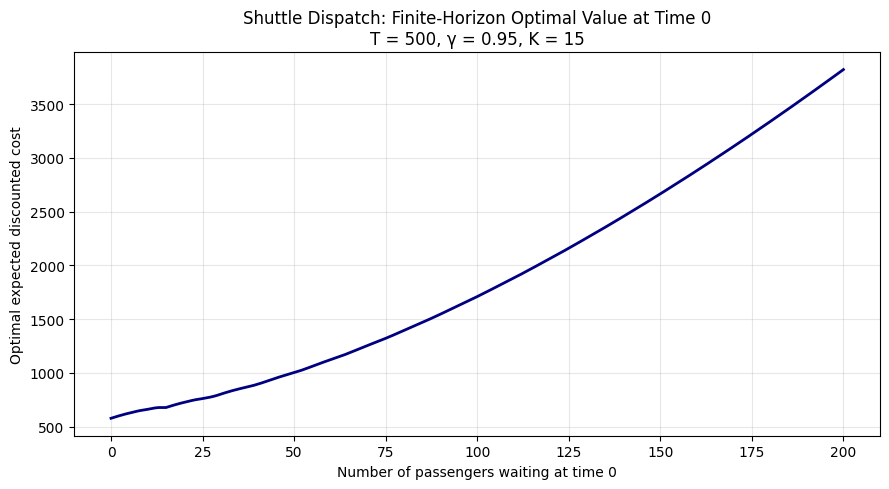

First dispatch state at time 0: 13
Dispatches at every state above it: True
Plot saved to: figures/part_a_finite_horizon_value.png


In [ ]:
from pathlib import Path

# Keep figures in one folder for the report.
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    STATES,
    V_finite[0],
    color="navy",
    linewidth=2
)

ax.set_xlabel("Number of passengers waiting at time 0")
ax.set_ylabel("Optimal expected discounted cost")
ax.set_title(
    "Shuttle Dispatch: Finite-Horizon Optimal Value at Time 0\n"
    f"T = {T}, γ = {GAMMA}, K = {K}"
)

ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "part_a_finite_horizon_value.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Check whether the time-0 policy has one dispatch threshold.
dispatch_states = STATES[policy_finite[0] == 1]

if len(dispatch_states) == 0:
    print("The time-0 policy never dispatches.")
else:
    threshold = int(dispatch_states[0])
    follows_threshold = np.all(policy_finite[0, threshold:] == 1)

    print("First dispatch state at time 0:", threshold)
    print("Dispatches at every state above it:", follows_threshold)

print("Plot saved to:", FIGURE_DIR / "part_a_finite_horizon_value.png")

In [ ]:
# Independent analytical predictions for the final two periods.

# Final period: wait, pay holding cost, then the horizon ends.
expected_last_period = C_H * STATES

# Penultimate period: wait now and wait in the final period.
# Calculate expected next queue directly, including the capacity cap.
expected_next_queue = np.array([
    sum(
        probability * min(int(state) + int(arrivals), MAX_QUEUE)
        for arrivals, probability in zip(ARRIVALS, ARRIVAL_PROBS)
    )
    for state in STATES
])

expected_penultimate = (
    C_H * STATES
    + GAMMA * C_H * expected_next_queue
)

last_period_error = np.max(
    np.abs(V_finite[T - 1] - expected_last_period)
)

penultimate_error = np.max(
    np.abs(V_finite[T - 2] - expected_penultimate)
)

print(f"Final-period maximum value error: {last_period_error:.3e}")
print(f"Penultimate-period maximum value error: {penultimate_error:.3e}")

print(
    "Wait everywhere in final period:",
    bool(np.all(policy_finite[T - 1] == 0))
)
print(
    "Wait everywhere in penultimate period:",
    bool(np.all(policy_finite[T - 2] == 0))
)

print(
    "Computed two-period cost at state 20:",
    round(float(V_finite[T - 2, 20]), 2)
)
print("Hand-calculated two-period cost at state 20: 83.70")

Final-period maximum value error: 0.000e+00
Penultimate-period maximum value error: 0.000e+00
Wait everywhere in final period: True
Wait everywhere in penultimate period: True
Computed two-period cost at state 20: 83.7
Hand-calculated two-period cost at state 20: 83.70


In [ ]:
# Infinite-horizon value iteration
TOLERANCE = 1e-8
MAX_ITERATIONS = 10_000

V_vi = np.zeros(MAX_QUEUE + 1)
vi_changes = []

for iteration in range(1, MAX_ITERATIONS + 1):
    V_new = np.zeros_like(V_vi)

    for state in STATES:
        action_costs = []

        for action in ACTIONS:
            expected_future_cost = sum(
                probability * V_vi[next_state(state, action, arrivals)]
                for arrivals, probability in zip(
                    ARRIVALS, ARRIVAL_PROBS
                )
            )

            action_costs.append(
                immediate_cost(state, action)
                + GAMMA * expected_future_cost
            )

        V_new[state] = min(action_costs)

    # Measure the largest change across all states.
    max_change = np.max(np.abs(V_new - V_vi))
    vi_changes.append(float(max_change))

    # Replace the old values only after all states are updated.
    V_vi = V_new

    if max_change < TOLERANCE:
        break
else:
    raise RuntimeError("Value iteration did not converge.")

# Extract a greedy policy using the final value estimates.
policy_vi = np.zeros(MAX_QUEUE + 1, dtype=int)

for state in STATES:
    action_costs = [
        immediate_cost(state, action)
        + GAMMA * sum(
            probability * V_vi[next_state(state, action, arrivals)]
            for arrivals, probability in zip(
                ARRIVALS, ARRIVAL_PROBS
            )
        )
        for action in ACTIONS
    ]

    policy_vi[state] = ACTIONS[np.argmin(action_costs)]

print("Converged after", iteration, "iterations")
print(f"Final maximum update: {max_change:.3e}")
print(f"Infinite-horizon cost at state 0: {V_vi[0]:.6f}")
print(f"Infinite-horizon cost at state 20: {V_vi[20]:.6f}")

print(
    "Maximum difference from the 500-period values:",
    f"{np.max(np.abs(V_vi - V_finite[0])):.3e}"
)

print(
    "Policy disagreements with the time-0 finite-horizon policy:",
    int(np.sum(policy_vi != policy_finite[0]))
)

Converged after 429 iterations
Final maximum update: 9.922e-09
Infinite-horizon cost at state 0: 576.670168
Infinite-horizon cost at state 20: 725.439658
Maximum difference from the 500-period values: 1.836e-07
Policy disagreements with the time-0 finite-horizon policy: 0


Bellman residual: 9.426e-09
VI maximum value-error bound: 1.885e-07
500-period omitted-tail bound: 7.274e-08
Combined comparison bound: 2.613e-07
Observed finite/VI difference: 1.836e-07
Difference within combined bound: True


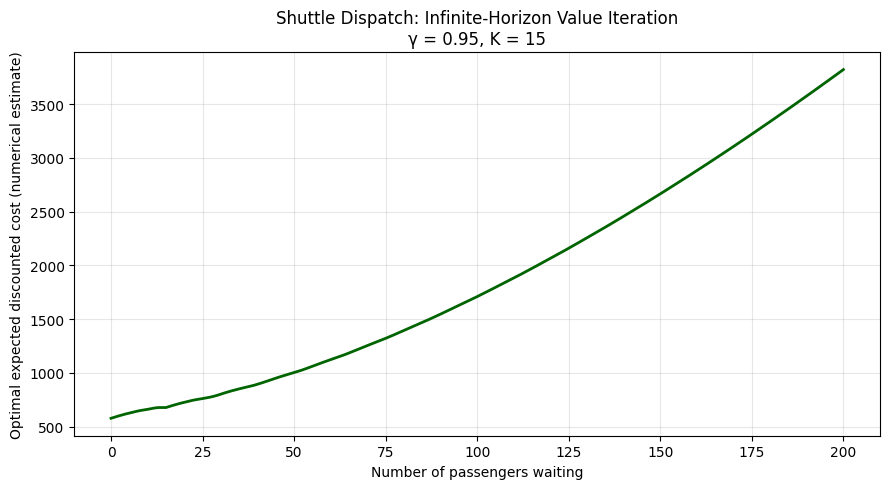

In [ ]:
# Apply one additional Bellman update without changing V_vi.
bellman_updated = np.zeros_like(V_vi)

for state in STATES:
    bellman_updated[state] = min(
        immediate_cost(state, action)
        + GAMMA * sum(
            probability * V_vi[next_state(state, action, arrivals)]
            for arrivals, probability in zip(
                ARRIVALS, ARRIVAL_PROBS
            )
        )
        for action in ACTIONS
    )

bellman_residual = np.max(np.abs(bellman_updated - V_vi))
vi_error_bound = bellman_residual / (1 - GAMMA)

# A conservative upper bound on any one-period cost:
# dispatch cost + holding cost for the maximum queue.
max_stage_cost_bound = C_F + C_H * MAX_QUEUE

# Bound on costs beyond the 500-period horizon.
finite_horizon_tail_bound = (
    max_stage_cost_bound * GAMMA**T / (1 - GAMMA)
)

observed_difference = np.max(np.abs(V_vi - V_finite[0]))
combined_error_bound = vi_error_bound + finite_horizon_tail_bound

print(f"Bellman residual: {bellman_residual:.3e}")
print(f"VI maximum value-error bound: {vi_error_bound:.3e}")
print(f"500-period omitted-tail bound: {finite_horizon_tail_bound:.3e}")
print(f"Combined comparison bound: {combined_error_bound:.3e}")
print(f"Observed finite/VI difference: {observed_difference:.3e}")
print(
    "Difference within combined bound:",
    bool(observed_difference <= combined_error_bound + 1e-10)
)

# Required plot for part (b).
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(STATES, V_vi, color="darkgreen", linewidth=2)

ax.set_xlabel("Number of passengers waiting")
ax.set_ylabel("Optimal expected discounted cost (numerical estimate)")
ax.set_title(
    "Shuttle Dispatch: Infinite-Horizon Value Iteration\n"
    f"γ = {GAMMA}, K = {K}"
)

ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "part_b_value_iteration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Start with the policy "wait in every state".
policy_pi = np.zeros(MAX_QUEUE + 1, dtype=int)
pi_changes = []

for pi_iteration in range(1, 101):

    # 1. POLICY EVALUATION
    P_pi = np.zeros((MAX_QUEUE + 1, MAX_QUEUE + 1))
    costs_pi = np.zeros(MAX_QUEUE + 1)

    for state in STATES:
        action = policy_pi[state]
        costs_pi[state] = immediate_cost(state, action)

        for arrivals, probability in zip(ARRIVALS, ARRIVAL_PROBS):
            new_state = next_state(state, action, arrivals)

            # += matters: several arrival outcomes can lead to
            # the same capped state, especially at the boundary.
            P_pi[state, new_state] += probability

    V_pi = np.linalg.solve(
        np.eye(MAX_QUEUE + 1) - GAMMA * P_pi,
        costs_pi
    )

    # 2. POLICY IMPROVEMENT
    improved_policy = policy_pi.copy()

    for state in STATES:
        action_costs = np.array([
            immediate_cost(state, action)
            + GAMMA * sum(
                probability
                * V_pi[next_state(state, action, arrivals)]
                for arrivals, probability in zip(
                    ARRIVALS, ARRIVAL_PROBS
                )
            )
            for action in ACTIONS
        ])

        best_action = int(ACTIONS[np.argmin(action_costs)])
        current_action = policy_pi[state]

        # Change only when the alternative is strictly better.
        # Retain the current action for numerical ties.
        if (
            action_costs[current_action]
            - action_costs[best_action]
            > 1e-10
        ):
            improved_policy[state] = best_action

    changed_states = int(np.sum(improved_policy != policy_pi))
    pi_changes.append(changed_states)

    print(
        f"Round {pi_iteration}: "
        f"{changed_states} states changed action"
    )

    if changed_states == 0:
        break

    policy_pi = improved_policy

else:
    raise RuntimeError("Policy iteration did not converge.")

print("\nPolicy iteration converged!")
print(f"Optimal cost at state 0: {V_pi[0]:.6f}")
print(f"Optimal cost at state 20: {V_pi[20]:.6f}")

print(
    "Maximum value difference from VI:",
    f"{np.max(np.abs(V_pi - V_vi)):.3e}"
)

print(
    "Policy disagreements with VI:",
    int(np.sum(policy_pi != policy_vi))
)

Round 1: 196 states changed action
Round 2: 28 states changed action
Round 3: 22 states changed action
Round 4: 7 states changed action
Round 5: 1 states changed action
Round 6: 0 states changed action

Policy iteration converged!
Optimal cost at state 0: 576.670168
Optimal cost at state 20: 725.439658
Maximum value difference from VI: 1.885e-07
Policy disagreements with VI: 0


First dispatch state: 13
Single-threshold policy: True


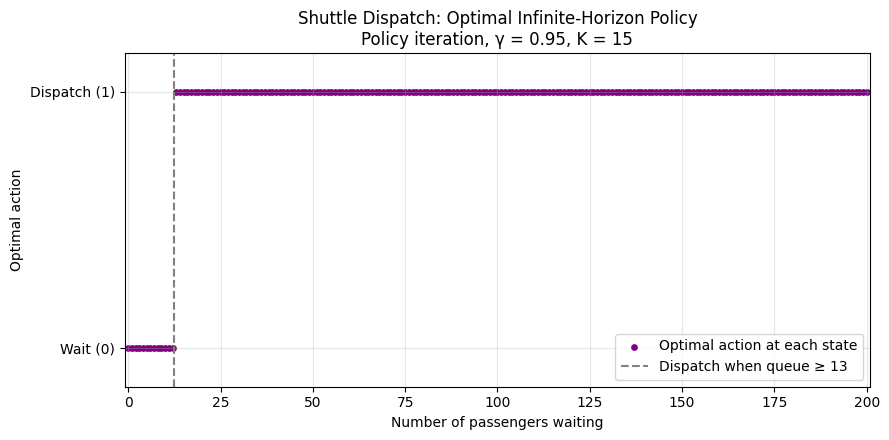

Policy plot and numerical results saved.


In [ ]:
dispatch_states_pi = STATES[policy_pi == 1]

if len(dispatch_states_pi) == 0:
    raise ValueError("No dispatch states found; inspect the policy.")

threshold_pi = int(dispatch_states_pi[0])

is_threshold_policy = (
    np.all(policy_pi[:threshold_pi] == 0)
    and np.all(policy_pi[threshold_pi:] == 1)
)

print("First dispatch state:", threshold_pi)
print("Single-threshold policy:", bool(is_threshold_policy))

# Plot each integer state's action.
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.scatter(
    STATES,
    policy_pi,
    color="purple",
    s=15,
    label="Optimal action at each state"
)

# Place the divider BETWEEN the last wait state and first dispatch state.
ax.axvline(
    threshold_pi - 0.5,
    color="gray",
    linestyle="--",
    label=f"Dispatch when queue ≥ {threshold_pi}"
)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Wait (0)", "Dispatch (1)"])
ax.set_ylim(-0.15, 1.15)
ax.set_xlim(-1, MAX_QUEUE + 1)

ax.set_xlabel("Number of passengers waiting")
ax.set_ylabel("Optimal action")
ax.set_title(
    "Shuttle Dispatch: Optimal Infinite-Horizon Policy\n"
    f"Policy iteration, γ = {GAMMA}, K = {K}"
)

ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "part_c_optimal_policy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results for reproducibility and later report tables.
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

np.savetxt(
    RESULTS_DIR / "shuttle_values_and_policy.csv",
    np.column_stack([
        STATES,
        V_finite[0],
        V_vi,
        V_pi,
        policy_pi
    ]),
    delimiter=",",
    header="state,finite_horizon_cost,VI_cost,PI_cost,PI_action",
    comments="",
    fmt=["%d", "%.12f", "%.12f", "%.12f", "%d"]
)

print("Policy plot and numerical results saved.")

In [ ]:
def solve_shuttle_vi(
    dispatch_cost=100,
    holding_cost=2,
    capacity=15,
    gamma=0.95,
    max_queue=200,
    tolerance=1e-8
):
    states = np.arange(max_queue + 1)
    arrivals = np.arange(1, 6)
    values = np.zeros(max_queue + 1)

    # Precompute costs and next states for both actions.
    remaining = np.maximum(
        states[:, None] - capacity * np.array([0, 1]),
        0
    )

    costs = (
        dispatch_cost * np.array([0, 1])
        + holding_cost * remaining
    )

    successors = np.minimum(
        remaining[:, :, None] + arrivals,
        max_queue
    )

    for iteration in range(1, 10_001):
        # Shape of action_values: (number of states, 2 actions).
        # Average over the five equally likely arrival outcomes.
        action_values = (
            costs + gamma * values[successors].mean(axis=2)
        )
        updated_values = action_values.min(axis=1)

        change = np.max(np.abs(updated_values - values))
        values = updated_values

        if change < tolerance:
            break
    else:
        raise RuntimeError("Value iteration did not converge.")

    # Extract the policy from the final values.
    final_action_values = (
        costs + gamma * values[successors].mean(axis=2)
    )
    policy = final_action_values.argmin(axis=1)

    return values, policy


# First verify that the reusable implementation reproduces our original.
V_check, policy_check = solve_shuttle_vi()

print("REPRODUCTION CHECK")
print(
    "Maximum difference from original VI:",
    f"{np.max(np.abs(V_check - V_vi)):.3e}"
)
print(
    "Policy disagreements:",
    int(np.sum(policy_check != policy_vi))
)

# Experiment 1: dispatch is free.
V_free_dispatch, policy_free_dispatch = solve_shuttle_vi(
    dispatch_cost=0
)

print("\nEXPERIMENT 1: FREE DISPATCH")
print(
    "Dispatches in all 200 nonempty states:",
    bool(np.all(policy_free_dispatch[1:] == 1))
)
print(
    "Number of nonempty states choosing dispatch:",
    int(np.sum(policy_free_dispatch[1:] == 1))
)
print(f"Cost from an empty station: {V_free_dispatch[0]:.6f}")

# Experiment 2: waiting is free.
V_free_wait, policy_free_wait = solve_shuttle_vi(
    holding_cost=0
)

print("\nEXPERIMENT 2: FREE WAITING")
print(
    "Waits in all 201 states:",
    bool(np.all(policy_free_wait == 0))
)
print(
    "Maximum absolute value across states:",
    f"{np.max(np.abs(V_free_wait)):.3e}"
)

REPRODUCTION CHECK
Maximum difference from original VI: 2.274e-12
Policy disagreements: 0

EXPERIMENT 1: FREE DISPATCH
Dispatches in all 200 nonempty states: True
Number of nonempty states choosing dispatch: 200
Cost from an empty station: 0.000000

EXPERIMENT 2: FREE WAITING
Waits in all 201 states: True
Maximum absolute value across states: 0.000e+00


In [ ]:
# Experiment 3: ignore all future costs.
V_gamma_zero, policy_gamma_zero = solve_shuttle_vi(gamma=0)

expected_gamma_zero = C_H * STATES

print("EXPERIMENT 3: ZERO DISCOUNT FACTOR")
print(
    "Waits in all 201 states:",
    bool(np.all(policy_gamma_zero == 0))
)
print(
    "Maximum error versus analytical value 2s:",
    f"{np.max(np.abs(V_gamma_zero - expected_gamma_zero)):.3e}"
)

# Experiment 4: a shuttle that cannot carry any passengers.
V_zero_capacity, policy_zero_capacity = solve_shuttle_vi(capacity=0)

# At state 200, the queue stays at 200 under our cap assumption.
# Waiting costs 400 each period, so its discounted cost is:
# 400 + gamma*400 + gamma^2*400 + ... = 400/(1-gamma).
expected_full_station_cost = C_H * MAX_QUEUE / (1 - GAMMA)

print("\nEXPERIMENT 4: ZERO SHUTTLE CAPACITY")
print(
    "Waits in all 201 states:",
    bool(np.all(policy_zero_capacity == 0))
)
print(f"Computed cost at state 200: {V_zero_capacity[200]:.6f}")
print(f"Analytical cost at state 200: {expected_full_station_cost:.6f}")
print(
    "Absolute error at state 200:",
    f"{abs(V_zero_capacity[200] - expected_full_station_cost):.3e}"
)

EXPERIMENT 3: ZERO DISCOUNT FACTOR
Waits in all 201 states: True
Maximum error versus analytical value 2s: 0.000e+00

EXPERIMENT 4: ZERO SHUTTLE CAPACITY
Waits in all 201 states: True
Computed cost at state 200: 8000.000000
Analytical cost at state 200: 8000.000000
Absolute error at state 200: 1.893e-07


In [ ]:
# Independent Monte Carlo validation of the computed policy.
rng = np.random.default_rng(2026)

N_RUNS = 5_000
SIM_HORIZON = 300

simulated_costs = np.zeros(N_RUNS)

for run in range(N_RUNS):
    queue = 0
    total_cost = 0.0
    discount = 1.0

    for step in range(SIM_HORIZON):
        action = int(policy_pi[queue])

        # Direct simulation of the physical system.
        served = min(queue, K) if action == 1 else 0
        remaining = queue - served

        period_cost = C_F * action + C_H * remaining
        total_cost += discount * period_cost

        arrivals = int(rng.integers(1, 6))
        queue = min(remaining + arrivals, MAX_QUEUE)

        discount *= GAMMA

    simulated_costs[run] = total_cost

# Sampling uncertainty of the estimated mean.
mc_mean = simulated_costs.mean()
mc_sd = simulated_costs.std(ddof=1)
mc_se = mc_sd / np.sqrt(N_RUNS)

ci_low = mc_mean - 1.96 * mc_se
ci_high = mc_mean + 1.96 * mc_se

# The simulation omits costs from period 300 onward.
# Costs are nonnegative, with a conservative per-period bound.
simulation_tail_bound = (
    (C_F + C_H * MAX_QUEUE)
    * GAMMA**SIM_HORIZON
    / (1 - GAMMA)
)

analytic_cost = float(V_pi[0])

print(f"Number of simulation runs: {N_RUNS}")
print(f"Simulated mean discounted cost: {mc_mean:.6f}")
print(f"Standard deviation across runs: {mc_sd:.6f}")
print(f"Standard error of the mean: {mc_se:.6f}")
print(f"Approximate 95% CI for 300-period mean: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Maximum omitted-tail cost: {simulation_tail_bound:.6f}")
print(f"Analytical infinite-horizon cost: {analytic_cost:.6f}")

print(
    "Analytical cost within tail-adjusted interval:",
    bool(ci_low <= analytic_cost <= ci_high + simulation_tail_bound)
)

# Preserve raw measurements for the report and GitHub.
np.savetxt(
    RESULTS_DIR / "shuttle_monte_carlo_costs.csv",
    simulated_costs,
    delimiter=",",
    header="discounted_cost_300_periods",
    comments=""
)

Number of simulation runs: 5000
Simulated mean discounted cost: 576.289616
Standard deviation across runs: 31.616584
Standard error of the mean: 0.447126
Approximate 95% CI for 300-period mean: [575.413249, 577.165983]
Maximum omitted-tail cost: 0.002075
Analytical infinite-horizon cost: 576.670168
Analytical cost within tail-adjusted interval: True


In [ ]:
# Sensitivity experiment: increase the queue cap from 200 to 400.
V_cap400, policy_cap400 = solve_shuttle_vi(max_queue=400)

# Use the same reusable solver's cap-200 result for a matched comparison.
low_states = np.arange(51)

low_state_value_difference = np.max(
    np.abs(V_check[low_states] - V_cap400[low_states])
)

low_state_policy_disagreements = np.sum(
    policy_check[low_states] != policy_cap400[low_states]
)

print("QUEUE-CAP SENSITIVITY: 200 VERSUS 400")
print(
    "Maximum value difference over states 0–50:",
    f"{low_state_value_difference:.3e}"
)
print(
    "Policy disagreements over states 0–50:",
    int(low_state_policy_disagreements)
)
print(f"Cost from empty station, cap 200: {V_check[0]:.6f}")
print(f"Cost from empty station, cap 400: {V_cap400[0]:.6f}")

QUEUE-CAP SENSITIVITY: 200 VERSUS 400
Maximum value difference over states 0–50: 0.000e+00
Policy disagreements over states 0–50: 0
Cost from empty station, cap 200: 576.670168
Cost from empty station, cap 400: 576.670168


In [ ]:
import json
import zipfile

shuttle_summary = {
    "parameters": {
        "capacity": K,
        "dispatch_cost": C_F,
        "holding_cost": C_H,
        "discount_factor": GAMMA,
        "queue_cap": MAX_QUEUE,
        "finite_horizon": T
    },
    "solution": {
        "dispatch_threshold": threshold_pi,
        "infinite_horizon_cost_state_0": float(V_pi[0]),
        "infinite_horizon_cost_state_20": float(V_pi[20]),
        "vi_sweeps": len(vi_changes),
        "pi_rounds": len(pi_changes)
    },
    "validation": {
        "final_period_error": float(last_period_error),
        "penultimate_period_error": float(penultimate_error),
        "vi_bellman_residual": float(bellman_residual),
        "vi_value_error_bound": float(vi_error_bound),
        "vi_pi_max_value_difference": float(
            np.max(np.abs(V_vi - V_pi))
        ),
        "vi_pi_policy_disagreements": int(
            np.sum(policy_vi != policy_pi)
        ),
        "free_dispatch_correct": bool(
            np.all(policy_free_dispatch[1:] == 1)
        ),
        "free_waiting_correct": bool(
            np.all(policy_free_wait == 0)
            and np.allclose(V_free_wait, 0)
        ),
        "gamma_zero_value_error": float(
            np.max(np.abs(V_gamma_zero - C_H * STATES))
        ),
        "zero_capacity_waits_everywhere": bool(
            np.all(policy_zero_capacity == 0)
        ),
        "zero_capacity_state_200_error": float(
            abs(V_zero_capacity[200] - expected_full_station_cost)
        ),
        "cap_sensitivity_low_state_value_difference": float(
            low_state_value_difference
        ),
        "cap_sensitivity_low_state_policy_disagreements": int(
            low_state_policy_disagreements
        )
    },
    "monte_carlo": {
        "seed": 2026,
        "runs": N_RUNS,
        "horizon": SIM_HORIZON,
        "mean": float(mc_mean),
        "standard_deviation": float(mc_sd),
        "standard_error": float(mc_se),
        "confidence_interval_95": [float(ci_low), float(ci_high)],
        "omitted_tail_bound": float(simulation_tail_bound)
    }
}

summary_path = RESULTS_DIR / "shuttle_summary.json"
summary_path.write_text(json.dumps(shuttle_summary, indent=2))

archive_path = Path("shuttle_results.zip")

with zipfile.ZipFile(
    archive_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for folder in [FIGURE_DIR, RESULTS_DIR]:
        for file_path in sorted(folder.rglob("*")):
            if file_path.is_file():
                archive.write(file_path, arcname=str(file_path))

print("Saved:", summary_path)
print("Created:", archive_path)
print("ZIP size:", archive_path.stat().st_size, "bytes")

Saved: results/shuttle_summary.json
Created: shuttle_results.zip
ZIP size: 427861 bytes


# Part 3(a): CartPole-v1 — Policy Gradient Without a Baseline

In [ ]:
%pip install -q "gymnasium[classic-control]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 91.0 MB/s eta 0:00:00


In [ ]:
import gymnasium as gym
import torch
import torch.nn as nn
from torch.distributions import Categorical

print("Gymnasium version:", gym.__version__)
print("PyTorch version:", torch.__version__)

# Create the exact environment required by the assignment.
env = gym.make("CartPole-v1")

state, info = env.reset(seed=42)

print("\nEnvironment:", env.spec.id)
print("Observation shape:", env.observation_space.shape)
print("Number of actions:", env.action_space.n)
print("Maximum episode steps:", env.spec.max_episode_steps)
print("Initial state:", state)

env.close()

Gymnasium version: 1.4.0
PyTorch version: 2.11.0+cpu

Environment: CartPole-v1
Observation shape: (4,)
Number of actions: 2
Maximum episode steps: 500
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]


In [ ]:
# Random-action reference: no neural network and no learning.
random_env = gym.make("CartPole-v1")
random_action_rng = np.random.default_rng(12345)

random_rewards = []
random_lengths = []
random_truncations = []

for episode in range(100):
    state, info = random_env.reset(seed=100_000 + episode)

    total_reward = 0.0
    steps = 0

    while True:
        # Equal probability of left (0) or right (1).
        action = int(random_action_rng.integers(0, 2))

        state, reward, terminated, truncated, info = random_env.step(
            action
        )

        total_reward += reward
        steps += 1

        # Stop on either failure or the environment's time limit.
        if terminated or truncated:
            break

    random_rewards.append(total_reward)
    random_lengths.append(steps)
    random_truncations.append(truncated)

random_env.close()

random_rewards = np.asarray(random_rewards)

print("Random-action episodes:", len(random_rewards))
print(f"Mean reward: {random_rewards.mean():.2f}")
print(f"Sample standard deviation: {random_rewards.std(ddof=1):.2f}")
print(f"Minimum reward: {random_rewards.min():.0f}")
print(f"Maximum reward: {random_rewards.max():.0f}")
print("Episodes reaching the 500-step limit:", sum(random_truncations))

# With default CartPole rewards, each executed step earns +1.
print(
    "Episode rewards equal episode lengths:",
    bool(np.allclose(random_rewards, random_lengths))
)

# Save the measurements.
np.savetxt(
    RESULTS_DIR / "cartpole_random_reference.csv",
    np.column_stack([
        np.arange(100_000, 100_100),
        random_rewards,
        random_lengths,
        random_truncations
    ]),
    delimiter=",",
    header="environment_seed,reward,length,truncated",
    comments="",
    fmt=["%d", "%.1f", "%d", "%d"]
)

Random-action episodes: 100
Mean reward: 20.44
Sample standard deviation: 9.93
Minimum reward: 10
Maximum reward: 57
Episodes reaching the 500-step limit: 0
Episode rewards equal episode lengths: True


In [ ]:
# Separate names keep CartPole settings distinct from shuttle parameters.
CP_SEED = 42
CP_GAMMA = 0.95
CP_LEARNING_RATE = 0.01

torch.manual_seed(CP_SEED)

# CPU is sufficient for this small network.
cp_device = torch.device("cpu")


class CartPolePolicy(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(4, 128),
            nn.Tanh(),
            nn.Linear(128, 2)
        )

    def forward(self, state):
        return self.network(state)


cp_policy = CartPolePolicy().to(cp_device)

cp_optimizer = torch.optim.Adam(
    cp_policy.parameters(),
    lr=CP_LEARNING_RATE
)

print(cp_policy)
print(
    "\nNumber of trainable parameters:",
    sum(p.numel() for p in cp_policy.parameters() if p.requires_grad)
)

# Inspect what the untrained network predicts for one state.
inspection_env = gym.make("CartPole-v1")
inspection_state, _ = inspection_env.reset(seed=CP_SEED)

state_tensor = torch.as_tensor(
    inspection_state,
    dtype=torch.float32,
    device=cp_device
)

with torch.no_grad():
    logits = cp_policy(state_tensor)
    action_distribution = Categorical(logits=logits)
    probabilities = action_distribution.probs

print("\nInitial state:", inspection_state)
print("Action probabilities [left, right]:", probabilities.numpy())
print("Sum of probabilities:", probabilities.sum().item())

inspection_env.close()

CartPolePolicy(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=2, bias=True)
  )
)

Number of trainable parameters: 898

Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Action probabilities [left, right]: [0.42083886 0.5791611 ]
Sum of probabilities: 1.0


In [ ]:
def discounted_returns(rewards, gamma):
    """Return-to-go for each time step in a completed episode."""
    returns = np.zeros(len(rewards), dtype=np.float64)
    running_return = 0.0

    # Work backward so each return uses the one immediately after it.
    for t in range(len(rewards) - 1, -1, -1):
        running_return = rewards[t] + gamma * running_return
        returns[t] = running_return

    return returns


# Test 1: independently calculated example.
example_rewards = [1.0, 2.0, 3.0]
expected_returns = np.array([2.75, 3.50, 3.00])
computed_returns = discounted_returns(example_rewards, gamma=0.5)

print("HAND-CALCULATED EXAMPLE")
print("Computed:", computed_returns)
print("Expected:", expected_returns)
print(
    "Maximum absolute error:",
    np.max(np.abs(computed_returns - expected_returns))
)

# Test 2: no future rewards should contribute when gamma = 0.
print("\nGAMMA = 0")
print("Computed:", discounted_returns(example_rewards, gamma=0.0))
print("Expected: [1. 2. 3.]")

# Test 3: without discounting, returns are remaining reward sums.
print("\nGAMMA = 1")
print("Computed:", discounted_returns(example_rewards, gamma=1.0))
print("Expected: [6. 5. 3.]")

# Test 4: CartPole earns +1 per step.
# A 10-step episode therefore has an analytical geometric-series return.
ten_step_returns = discounted_returns(np.ones(10), CP_GAMMA)
expected_start_return = (1 - CP_GAMMA**10) / (1 - CP_GAMMA)

print("\nTEN-STEP CARTPOLE EXAMPLE")
print(f"Computed starting return: {ten_step_returns[0]:.8f}")
print(f"Analytical starting return: {expected_start_return:.8f}")
print(f"Final-step return: {ten_step_returns[-1]:.1f}")

HAND-CALCULATED EXAMPLE
Computed: [2.75 3.5  3.  ]
Expected: [2.75 3.5  3.  ]
Maximum absolute error: 0.0

GAMMA = 0
Computed: [1. 2. 3.]
Expected: [1. 2. 3.]

GAMMA = 1
Computed: [6. 5. 3.]
Expected: [6. 5. 3.]

TEN-STEP CARTPOLE EXAMPLE
Computed starting return: 8.02526122
Analytical starting return: 8.02526122
Final-step return: 1.0


In [ ]:
def collect_cartpole_episode(env, policy, reset_seed):
    state, _ = env.reset(seed=reset_seed)

    states = []
    actions = []
    rewards = []
    log_probs = []
    action_probabilities = []

    while True:
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=cp_device
        )

        distribution = Categorical(logits=policy(state_tensor))
        action = distribution.sample()

        next_state, reward, terminated, truncated, _ = env.step(
            int(action.item())
        )

        states.append(state.copy())
        actions.append(int(action.item()))
        rewards.append(float(reward))

        # Keep the computation graph for the training loss.
        log_probs.append(distribution.log_prob(action))

        # Detach only the probabilities saved for inspection.
        action_probabilities.append(
            distribution.probs.detach().cpu().numpy()
        )

        state = next_state

        if terminated or truncated:
            break

    return {
        "states": np.asarray(states),
        "actions": np.asarray(actions),
        "rewards": np.asarray(rewards),
        "log_probs": torch.stack(log_probs),
        "probabilities": np.asarray(action_probabilities),
        "terminated": terminated,
        "truncated": truncated
    }


def reinforce_loss(log_probs, rewards, gamma):
    returns = torch.as_tensor(
        discounted_returns(rewards, gamma),
        dtype=log_probs.dtype,
        device=log_probs.device
    )

    time_weights = gamma ** torch.arange(
        len(rewards),
        dtype=log_probs.dtype,
        device=log_probs.device
    )

    # No baseline, centering, or return normalization.
    return -(time_weights * returns * log_probs).sum()


# Collect a diagnostic episode using a dedicated seed.
torch.manual_seed(54321)
diagnostic_env = gym.make("CartPole-v1")

diagnostic_episode = collect_cartpole_episode(
    diagnostic_env, cp_policy, reset_seed=200_000
)
diagnostic_env.close()

diagnostic_returns = discounted_returns(
    diagnostic_episode["rewards"], CP_GAMMA
)

print("Episode reward:", diagnostic_episode["rewards"].sum())
print("Terminated:", diagnostic_episode["terminated"])
print("Truncated:", diagnostic_episode["truncated"])

print("\nFirst 10 steps:")
print(" t | action | P(left) | P(right) | reward | return-to-go")

for t in range(min(10, len(diagnostic_returns))):
    probabilities = diagnostic_episode["probabilities"][t]

    print(
        f"{t:2d} | "
        f"{diagnostic_episode['actions'][t]:6d} | "
        f"{probabilities[0]:7.3f} | "
        f"{probabilities[1]:8.3f} | "
        f"{diagnostic_episode['rewards'][t]:6.1f} | "
        f"{diagnostic_returns[t]:12.4f}"
    )

# Check that the loss produces finite gradients.
cp_optimizer.zero_grad(set_to_none=True)

diagnostic_loss = reinforce_loss(
    diagnostic_episode["log_probs"],
    diagnostic_episode["rewards"],
    CP_GAMMA
)
diagnostic_loss.backward()

gradient_norm = torch.sqrt(sum(
    parameter.grad.square().sum()
    for parameter in cp_policy.parameters()
    if parameter.grad is not None
))

print(f"\nLoss: {diagnostic_loss.item():.6f}")
print(f"Gradient norm: {gradient_norm.item():.6f}")
print("Gradient norm is finite:", bool(torch.isfinite(gradient_norm)))

# Clear diagnostic gradients; no optimizer.step() is performed.
cp_optimizer.zero_grad(set_to_none=True)
print("Network weights have NOT been updated.")

Episode reward: 16.0
Terminated: True
Truncated: False

First 10 steps:
 t | action | P(left) | P(right) | reward | return-to-go
 0 |      0 |   0.419 |    0.581 |    1.0 |      11.1975
 1 |      1 |   0.457 |    0.543 |    1.0 |      10.7342
 2 |      0 |   0.420 |    0.580 |    1.0 |      10.2465
 3 |      0 |   0.458 |    0.542 |    1.0 |       9.7332
 4 |      0 |   0.497 |    0.503 |    1.0 |       9.1928
 5 |      0 |   0.534 |    0.466 |    1.0 |       8.6240
 6 |      1 |   0.569 |    0.431 |    1.0 |       8.0253
 7 |      0 |   0.538 |    0.462 |    1.0 |       7.3950
 8 |      1 |   0.572 |    0.428 |    1.0 |       6.7316
 9 |      1 |   0.542 |    0.458 |    1.0 |       6.0333

Loss: 62.454773
Gradient norm: 62.428841
Gradient norm is finite: True
Network weights have NOT been updated.


In [ ]:
import csv
import json
import time
from pathlib import Path

CP_TRAIN_EPISODES = 1_000
CP_BATCH_SIZE = 8

run_dir = Path("cartpole_runs/no_baseline_seed42_lr001")

# Prevent accidentally overwriting a completed or interrupted run.
if run_dir.exists():
    raise FileExistsError(
        f"{run_dir} already exists. "
        "Keep its results; ask me how to resume or start a separate run."
    )

run_dir.mkdir(parents=True)

torch.set_num_threads(1)
torch.manual_seed(CP_SEED)

# Fresh, reproducible initialization for the training experiment.
cp_policy = CartPolePolicy().to(cp_device)
cp_optimizer = torch.optim.Adam(
    cp_policy.parameters(),
    lr=CP_LEARNING_RATE
)

training_config = {
    "environment": "CartPole-v1",
    "seed": CP_SEED,
    "episodes": CP_TRAIN_EPISODES,
    "batch_size": CP_BATCH_SIZE,
    "learning_rate": CP_LEARNING_RATE,
    "gamma": CP_GAMMA,
    "baseline": None,
    "return_normalization": False,
    "loss": "-sum_t gamma^t * G_t * log_prob_t",
    "hidden_units": 128,
    "activation": "Tanh",
    "device": str(cp_device),
    "gymnasium_version": gym.__version__,
    "torch_version": str(torch.__version__),
    "environment_seed_start": 300_000
}

(run_dir / "config.json").write_text(
    json.dumps(training_config, indent=2)
)

cp_training_rewards = []
train_env = gym.make("CartPole-v1")
start_time = time.time()

try:
    with (run_dir / "training.csv").open("w", newline="") as log_file:
        writer = csv.writer(log_file)
        writer.writerow([
            "episode", "environment_seed", "reward",
            "discounted_return", "length",
            "terminated", "truncated", "batch_gradient_norm"
        ])

        for batch_start in range(
            0, CP_TRAIN_EPISODES, CP_BATCH_SIZE
        ):
            batch_end = min(
                batch_start + CP_BATCH_SIZE,
                CP_TRAIN_EPISODES
            )

            # Keep the policy fixed while collecting this batch.
            batch = [
                collect_cartpole_episode(
                    train_env,
                    cp_policy,
                    reset_seed=300_000 + episode_index
                )
                for episode_index in range(batch_start, batch_end)
            ]

            cp_optimizer.zero_grad(set_to_none=True)

            batch_loss = torch.stack([
                reinforce_loss(
                    episode["log_probs"],
                    episode["rewards"],
                    CP_GAMMA
                )
                for episode in batch
            ]).mean()

            batch_loss.backward()

            grad_norm = torch.sqrt(sum(
                parameter.grad.square().sum()
                for parameter in cp_policy.parameters()
                if parameter.grad is not None
            ))

            if not torch.isfinite(grad_norm).item():
                raise FloatingPointError(
                    "Nonfinite gradient detected; training stopped."
                )

            cp_optimizer.step()

            # Record every episode, not just batch averages.
            for episode_index, episode in zip(
                range(batch_start, batch_end), batch
            ):
                score = float(episode["rewards"].sum())
                cp_training_rewards.append(score)

                writer.writerow([
                    episode_index + 1,
                    300_000 + episode_index,
                    score,
                    discounted_returns(
                        episode["rewards"], CP_GAMMA
                    )[0],
                    len(episode["rewards"]),
                    episode["terminated"],
                    episode["truncated"],
                    grad_norm.item()
                ])

            log_file.flush()

            if batch_end % 200 == 0 or batch_end == CP_TRAIN_EPISODES:
                torch.save(
                    {
                        "completed_episodes": batch_end,
                        "policy_state_dict": cp_policy.state_dict(),
                        "optimizer_state_dict": cp_optimizer.state_dict(),
                        "torch_rng_state": torch.get_rng_state(),
                        "config": training_config
                    },
                    run_dir / f"checkpoint_{batch_end:04d}.pt"
                )

                print(
                    f"Episode {batch_end:4d} | "
                    f"Last 100 mean reward: "
                    f"{np.mean(cp_training_rewards[-100:]):7.2f} | "
                    f"Gradient norm: {grad_norm.item():8.2f}",
                    flush=True
                )

finally:
    train_env.close()

print(f"\nTraining time: {time.time() - start_time:.1f} seconds")
print("Results saved in:", run_dir)

Episode  200 | Last 100 mean reward:   40.04 | Gradient norm:    50.11
Episode  400 | Last 100 mean reward:  111.27 | Gradient norm:    77.90
Episode  600 | Last 100 mean reward:   86.57 | Gradient norm:    51.28
Episode  800 | Last 100 mean reward:  286.65 | Gradient norm:     7.96
Episode 1000 | Last 100 mean reward:  138.64 | Gradient norm:    89.53

Training time: 117.5 seconds
Results saved in: cartpole_runs/no_baseline_seed42_lr001


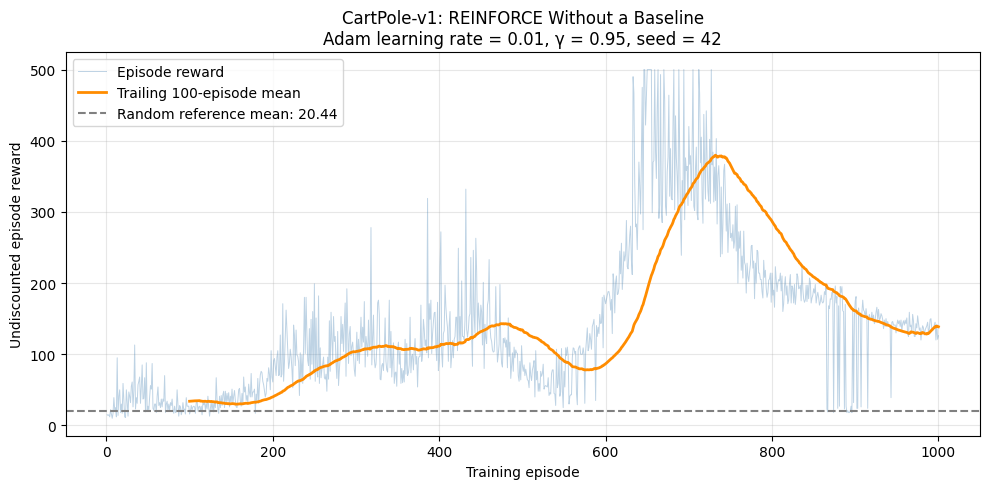

First 100-episode mean: 33.94
Last 100-episode mean: 138.64
Highest 100-episode moving average: 379.70
Episode where that window ends: 732
Training episodes reaching reward 500: 17
Learning curve saved to: cartpole_runs/no_baseline_seed42_lr001/learning_curve.png


In [ ]:
# Read the saved log so the figure is reproducible from disk.
training_data = np.genfromtxt(
    run_dir / "training.csv",
    delimiter=",",
    names=True
)

episode_numbers = training_data["episode"].astype(int)
episode_rewards = training_data["reward"]

# Full trailing windows only: the first average ends at episode 100.
window = 100
moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    episode_numbers,
    episode_rewards,
    color="steelblue",
    alpha=0.35,
    linewidth=0.7,
    label="Episode reward"
)

ax.plot(
    episode_numbers[window - 1:],
    moving_average,
    color="darkorange",
    linewidth=2,
    label="Trailing 100-episode mean"
)

ax.axhline(
    random_rewards.mean(),
    color="gray",
    linestyle="--",
    label=f"Random reference mean: {random_rewards.mean():.2f}"
)

ax.set_xlabel("Training episode")
ax.set_ylabel("Undiscounted episode reward")
ax.set_title(
    "CartPole-v1: REINFORCE Without a Baseline\n"
    "Adam learning rate = 0.01, γ = 0.95, seed = 42"
)

ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    run_dir / "learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

best_window_index = int(np.argmax(moving_average))

print(f"First 100-episode mean: {episode_rewards[:100].mean():.2f}")
print(f"Last 100-episode mean: {episode_rewards[-100:].mean():.2f}")
print(f"Highest 100-episode moving average: {moving_average.max():.2f}")
print(
    "Episode where that window ends:",
    episode_numbers[window - 1 + best_window_index]
)
print(
    "Training episodes reaching reward 500:",
    int(np.sum(episode_rewards == 500))
)
print("Learning curve saved to:", run_dir / "learning_curve.png")

In [ ]:
def evaluate_cartpole_policy(
    policy,
    n_episodes,
    environment_seed_start,
    action_seed
):
    """Evaluate a frozen stochastic policy without learning."""
    evaluation_env = gym.make("CartPole-v1")
    scores = []
    was_training = policy.training
    policy.eval()

    try:
        # Preserve the notebook's existing PyTorch random state.
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(action_seed)

            with torch.no_grad():
                for episode_index in range(n_episodes):
                    state, _ = evaluation_env.reset(
                        seed=environment_seed_start + episode_index
                    )
                    total_reward = 0.0

                    while True:
                        state_tensor = torch.as_tensor(
                            state,
                            dtype=torch.float32,
                            device=cp_device
                        )

                        distribution = Categorical(
                            logits=policy(state_tensor)
                        )
                        action = int(distribution.sample().item())

                        state, reward, terminated, truncated, _ = (
                            evaluation_env.step(action)
                        )
                        total_reward += reward

                        if terminated or truncated:
                            break

                    scores.append(total_reward)
    finally:
        evaluation_env.close()
        policy.train(was_training)

    return np.asarray(scores)


validation_rows = []

print("Checkpoint | Mean reward | Sample SD | Reached 500")
print("-" * 59)

# Use a separate model so the current training model stays untouched.
with torch.random.fork_rng(devices=[]):
    validation_policy = CartPolePolicy().to(cp_device)

for checkpoint_episode in [200, 400, 600, 800, 1000]:
    checkpoint_path = (
        run_dir / f"checkpoint_{checkpoint_episode:04d}.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=cp_device,
        weights_only=True
    )

    validation_policy.load_state_dict(
        checkpoint["policy_state_dict"]
    )

    scores = evaluate_cartpole_policy(
        validation_policy,
        n_episodes=50,
        environment_seed_start=7_000_000,
        action_seed=70_001
    )

    mean_score = float(scores.mean())
    sd_score = float(scores.std(ddof=1))
    success_rate = float(np.mean(scores == 500))

    validation_rows.append([
        checkpoint_episode,
        mean_score,
        sd_score,
        success_rate
    ])

    np.savetxt(
        run_dir / f"validation_scores_{checkpoint_episode:04d}.csv",
        scores,
        delimiter=",",
        header="episode_reward",
        comments=""
    )

    print(
        f"{checkpoint_episode:10d} | "
        f"{mean_score:11.2f} | "
        f"{sd_score:9.2f} | "
        f"{success_rate:10.1%}",
        flush=True
    )

np.savetxt(
    run_dir / "checkpoint_validation_summary.csv",
    np.asarray(validation_rows),
    delimiter=",",
    header="checkpoint_episode,mean_reward,sample_sd,fraction_reaching_500",
    comments="",
    fmt=["%d", "%.6f", "%.6f", "%.6f"]
)

Checkpoint | Mean reward | Sample SD | Reached 500
-----------------------------------------------------------
       200 |       92.58 |     36.82 |       0.0%
       400 |      143.22 |     45.00 |       0.0%
       600 |      172.58 |     16.03 |       0.0%
       800 |      189.38 |     17.13 |       0.0%
      1000 |      132.38 |      7.20 |       0.0%


In [ ]:
# Preserve the first experiment's location.
cp_lr001_run_dir = Path("cartpole_runs/no_baseline_seed42_lr001")

# Change only the learning rate for this experiment.
CP_LEARNING_RATE = 0.003

In [ ]:
import csv
import json
import time
from pathlib import Path

# Matched experiment: only the learning rate changes.
CP_LEARNING_RATE = 0.003
CP_TRAIN_EPISODES = 1_000
CP_BATCH_SIZE = 8

run_dir = Path("cartpole_runs/no_baseline_seed42_lr0003")

if run_dir.exists():
    raise FileExistsError(
        f"{run_dir} already exists. "
        "Stop here and send me this message so we preserve that run."
    )

run_dir.mkdir(parents=True)

torch.set_num_threads(1)

# Same seed and initial network weights as the first experiment.
torch.manual_seed(CP_SEED)
cp_policy = CartPolePolicy().to(cp_device)

cp_optimizer = torch.optim.Adam(
    cp_policy.parameters(),
    lr=CP_LEARNING_RATE
)

training_config = {
    "environment": "CartPole-v1",
    "seed": CP_SEED,
    "episodes": CP_TRAIN_EPISODES,
    "batch_size": CP_BATCH_SIZE,
    "learning_rate": CP_LEARNING_RATE,
    "gamma": CP_GAMMA,
    "baseline": None,
    "return_normalization": False,
    "loss": "-sum_t gamma^t * G_t * log_prob_t",
    "hidden_units": 128,
    "activation": "Tanh",
    "device": str(cp_device),
    "gymnasium_version": gym.__version__,
    "torch_version": str(torch.__version__),
    "environment_seed_start": 300_000
}

(run_dir / "config.json").write_text(
    json.dumps(training_config, indent=2)
)

cp_training_rewards = []
train_env = gym.make("CartPole-v1")
start_time = time.time()

try:
    with (run_dir / "training.csv").open("w", newline="") as log_file:
        writer = csv.writer(log_file)
        writer.writerow([
            "episode", "environment_seed", "reward",
            "discounted_return", "length",
            "terminated", "truncated", "batch_gradient_norm"
        ])

        for batch_start in range(
            0, CP_TRAIN_EPISODES, CP_BATCH_SIZE
        ):
            batch_end = min(
                batch_start + CP_BATCH_SIZE,
                CP_TRAIN_EPISODES
            )

            batch = [
                collect_cartpole_episode(
                    train_env,
                    cp_policy,
                    reset_seed=300_000 + episode_index
                )
                for episode_index in range(batch_start, batch_end)
            ]

            cp_optimizer.zero_grad(set_to_none=True)

            batch_loss = torch.stack([
                reinforce_loss(
                    episode["log_probs"],
                    episode["rewards"],
                    CP_GAMMA
                )
                for episode in batch
            ]).mean()

            batch_loss.backward()

            grad_norm = torch.sqrt(sum(
                parameter.grad.square().sum()
                for parameter in cp_policy.parameters()
                if parameter.grad is not None
            ))

            if not torch.isfinite(grad_norm).item():
                raise FloatingPointError(
                    "Nonfinite gradient detected; training stopped."
                )

            cp_optimizer.step()

            for episode_index, episode in zip(
                range(batch_start, batch_end), batch
            ):
                score = float(episode["rewards"].sum())
                cp_training_rewards.append(score)

                writer.writerow([
                    episode_index + 1,
                    300_000 + episode_index,
                    score,
                    discounted_returns(
                        episode["rewards"], CP_GAMMA
                    )[0],
                    len(episode["rewards"]),
                    episode["terminated"],
                    episode["truncated"],
                    grad_norm.item()
                ])

            log_file.flush()

            if batch_end % 200 == 0 or batch_end == CP_TRAIN_EPISODES:
                torch.save(
                    {
                        "completed_episodes": batch_end,
                        "policy_state_dict": cp_policy.state_dict(),
                        "optimizer_state_dict": cp_optimizer.state_dict(),
                        "torch_rng_state": torch.get_rng_state(),
                        "config": training_config
                    },
                    run_dir / f"checkpoint_{batch_end:04d}.pt"
                )

                print(
                    f"Episode {batch_end:4d} | "
                    f"Last 100 mean reward: "
                    f"{np.mean(cp_training_rewards[-100:]):7.2f} | "
                    f"Gradient norm: {grad_norm.item():8.2f}",
                    flush=True
                )

finally:
    train_env.close()

print(f"\nTraining time: {time.time() - start_time:.1f} seconds")
print("Results saved in:", run_dir)

Episode  200 | Last 100 mean reward:   57.96 | Gradient norm:    27.39
Episode  400 | Last 100 mean reward:   73.14 | Gradient norm:    12.48
Episode  600 | Last 100 mean reward:  122.31 | Gradient norm:    45.37
Episode  800 | Last 100 mean reward:  188.76 | Gradient norm:    90.95
Episode 1000 | Last 100 mean reward:   71.69 | Gradient norm:    18.68

Training time: 76.9 seconds
Results saved in: cartpole_runs/no_baseline_seed42_lr0003


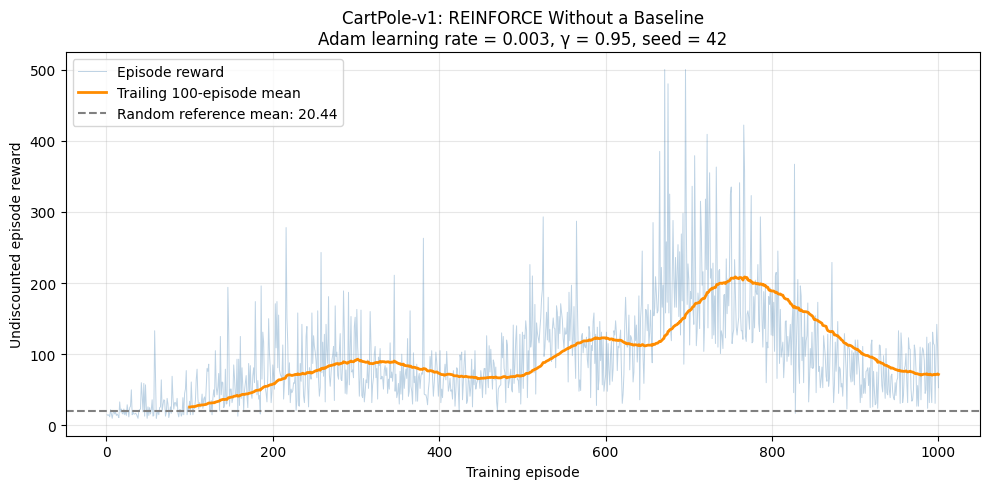

Checkpoint | Mean reward | Sample SD | Reached 500
-----------------------------------------------------------
       200 |       78.62 |     41.35 |       0.0%
       400 |       67.90 |     28.99 |       0.0%
       600 |       94.82 |     36.92 |       0.0%
       800 |      146.54 |     75.00 |       2.0%
      1000 |       98.76 |     39.47 |       0.0%


In [ ]:
# Explicit path avoids accidentally evaluating the first experiment.
lr003_dir = Path("cartpole_runs/no_baseline_seed42_lr0003")

# 1. Plot the training rewards.
lr003_data = np.genfromtxt(
    lr003_dir / "training.csv",
    delimiter=",",
    names=True
)

lr003_rewards = lr003_data["reward"]
lr003_episodes = lr003_data["episode"].astype(int)

lr003_moving_average = np.convolve(
    lr003_rewards,
    np.ones(100) / 100,
    mode="valid"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    lr003_episodes,
    lr003_rewards,
    color="steelblue",
    alpha=0.35,
    linewidth=0.7,
    label="Episode reward"
)

ax.plot(
    lr003_episodes[99:],
    lr003_moving_average,
    color="darkorange",
    linewidth=2,
    label="Trailing 100-episode mean"
)

ax.axhline(
    random_rewards.mean(),
    color="gray",
    linestyle="--",
    label=f"Random reference mean: {random_rewards.mean():.2f}"
)

ax.set_xlabel("Training episode")
ax.set_ylabel("Undiscounted episode reward")
ax.set_title(
    "CartPole-v1: REINFORCE Without a Baseline\n"
    "Adam learning rate = 0.003, γ = 0.95, seed = 42"
)

ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    lr003_dir / "learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Evaluate frozen checkpoints on the existing validation set.
# This uses the evaluation function defined earlier.
with torch.random.fork_rng(devices=[]):
    lr003_validation_policy = CartPolePolicy().to(cp_device)

lr003_validation_rows = []

print("Checkpoint | Mean reward | Sample SD | Reached 500")
print("-" * 59)

for checkpoint_episode in [200, 400, 600, 800, 1000]:
    checkpoint = torch.load(
        lr003_dir / f"checkpoint_{checkpoint_episode:04d}.pt",
        map_location=cp_device,
        weights_only=True
    )

    lr003_validation_policy.load_state_dict(
        checkpoint["policy_state_dict"]
    )

    scores = evaluate_cartpole_policy(
        lr003_validation_policy,
        n_episodes=50,
        environment_seed_start=7_000_000,
        action_seed=70_001
    )

    mean_score = float(scores.mean())
    sd_score = float(scores.std(ddof=1))
    success_rate = float(np.mean(scores == 500))

    lr003_validation_rows.append([
        checkpoint_episode,
        mean_score,
        sd_score,
        success_rate
    ])

    np.savetxt(
        lr003_dir / f"validation_scores_{checkpoint_episode:04d}.csv",
        scores,
        delimiter=",",
        header="episode_reward",
        comments=""
    )

    print(
        f"{checkpoint_episode:10d} | "
        f"{mean_score:11.2f} | "
        f"{sd_score:9.2f} | "
        f"{success_rate:10.1%}",
        flush=True
    )

np.savetxt(
    lr003_dir / "checkpoint_validation_summary.csv",
    np.asarray(lr003_validation_rows),
    delimiter=",",
    header="checkpoint_episode,mean_reward,sample_sd,fraction_reaching_500",
    comments="",
    fmt=["%d", "%.6f", "%.6f", "%.6f"]
)

FINAL EVALUATION: CARTPOLE WITHOUT A BASELINE
Selected learning rate: 0.01
Selected checkpoint: episode 800
Evaluation episodes: 500
Mean reward: 191.86
Sample standard deviation: 16.28
Approximate 95% CI for mean: [190.43, 193.28]
Minimum reward: 151
Maximum reward: 244
Episodes reaching 500 steps: 0.0%


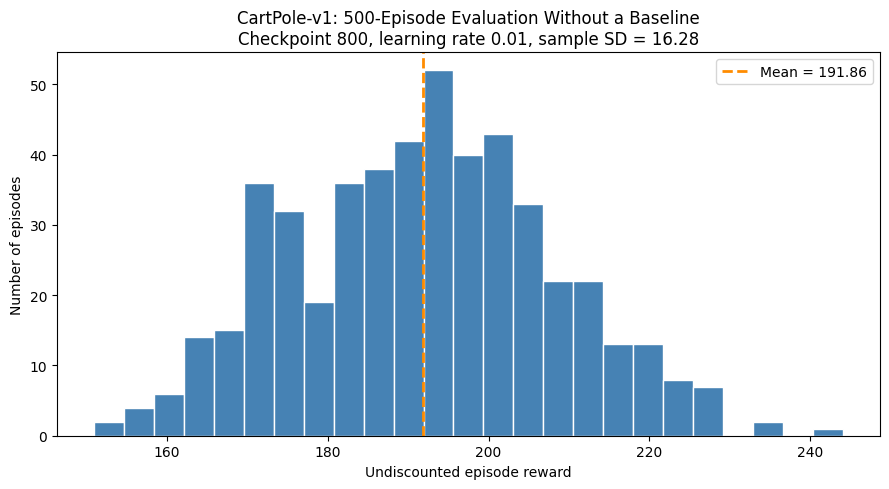

Evaluation files saved in: cartpole_runs/no_baseline_seed42_lr001/final_evaluation_checkpoint0800


In [ ]:
# Freeze the model selected using validation results.
selected_run_dir = Path("cartpole_runs/no_baseline_seed42_lr001")
selected_checkpoint_path = selected_run_dir / "checkpoint_0800.pt"

final_eval_dir = selected_run_dir / "final_evaluation_checkpoint0800"

if final_eval_dir.exists():
    raise FileExistsError(
        "This final evaluation folder already exists. "
        "Stop and send me the message so we preserve the results."
    )

final_eval_dir.mkdir(parents=True)

with torch.random.fork_rng(devices=[]):
    cp_selected_policy = CartPolePolicy().to(cp_device)

selected_checkpoint = torch.load(
    selected_checkpoint_path,
    map_location=cp_device,
    weights_only=True
)

cp_selected_policy.load_state_dict(
    selected_checkpoint["policy_state_dict"]
)

# Fresh seeds, separate from training and validation.
cp_final_scores = evaluate_cartpole_policy(
    cp_selected_policy,
    n_episodes=500,
    environment_seed_start=9_000_000,
    action_seed=90_001
)

final_mean = float(cp_final_scores.mean())
final_sd = float(cp_final_scores.std(ddof=1))
final_se = final_sd / np.sqrt(len(cp_final_scores))

final_ci_low = final_mean - 1.96 * final_se
final_ci_high = final_mean + 1.96 * final_se
final_success_rate = float(np.mean(cp_final_scores == 500))

print("FINAL EVALUATION: CARTPOLE WITHOUT A BASELINE")
print("Selected learning rate: 0.01")
print("Selected checkpoint: episode 800")
print("Evaluation episodes:", len(cp_final_scores))
print(f"Mean reward: {final_mean:.2f}")
print(f"Sample standard deviation: {final_sd:.2f}")
print(
    f"Approximate 95% CI for mean: "
    f"[{final_ci_low:.2f}, {final_ci_high:.2f}]"
)
print(f"Minimum reward: {cp_final_scores.min():.0f}")
print(f"Maximum reward: {cp_final_scores.max():.0f}")
print(f"Episodes reaching 500 steps: {final_success_rate:.1%}")

# Required histogram.
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    cp_final_scores,
    bins=25,
    color="steelblue",
    edgecolor="white"
)

ax.axvline(
    final_mean,
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label=f"Mean = {final_mean:.2f}"
)

ax.set_xlabel("Undiscounted episode reward")
ax.set_ylabel("Number of episodes")
ax.set_title(
    "CartPole-v1: 500-Episode Evaluation Without a Baseline\n"
    f"Checkpoint 800, learning rate 0.01, sample SD = {final_sd:.2f}"
)

ax.legend()
fig.tight_layout()
fig.savefig(
    final_eval_dir / "reward_histogram.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save raw scores and the evaluation protocol.
np.savetxt(
    final_eval_dir / "episode_scores.csv",
    np.column_stack([
        np.arange(9_000_000, 9_000_500),
        cp_final_scores
    ]),
    delimiter=",",
    header="environment_seed,episode_reward",
    comments="",
    fmt=["%d", "%.1f"]
)

evaluation_summary = {
    "environment": "CartPole-v1",
    "checkpoint": str(selected_checkpoint_path),
    "selection_rule": (
        "Highest mean reward over 50 validation episodes among "
        "checkpoints 200, 400, 600, 800, 1000 at learning rates "
        "0.01 and 0.003; training seed 42."
    ),
    "evaluation_episodes": 500,
    "environment_seed_start": 9_000_000,
    "action_seed": 90_001,
    "action_selection": "sampled from frozen policy",
    "mean_reward": final_mean,
    "sample_standard_deviation": final_sd,
    "mean_confidence_interval_95": [final_ci_low, final_ci_high],
    "fraction_reaching_500": final_success_rate
}

(final_eval_dir / "summary.json").write_text(
    json.dumps(evaluation_summary, indent=2)
)

print("Evaluation files saved in:", final_eval_dir)

In [ ]:
BASELINE_ALPHA = 0.1


def reinforce_loss_with_baseline(
    log_probs, rewards, gamma, baseline
):
    returns = torch.as_tensor(
        discounted_returns(rewards, gamma),
        dtype=log_probs.dtype,
        device=log_probs.device
    )

    baseline_values = torch.as_tensor(
        baseline[:len(rewards)].copy(),
        dtype=log_probs.dtype,
        device=log_probs.device
    )

    advantages = returns - baseline_values

    time_weights = gamma ** torch.arange(
        len(rewards),
        dtype=log_probs.dtype,
        device=log_probs.device
    )

    return -(time_weights * advantages * log_probs).sum()


def update_time_baseline(
    baseline, reward_sequences, gamma, alpha=BASELINE_ALPHA
):
    """Update only timesteps reached by at least one episode."""
    sums = np.zeros_like(baseline)
    counts = np.zeros_like(baseline)

    for rewards in reward_sequences:
        returns = discounted_returns(rewards, gamma)
        length = len(returns)

        sums[:length] += returns
        counts[:length] += 1

    visited = counts > 0
    updated = baseline.copy()

    updated[visited] = (
        (1 - alpha) * baseline[visited]
        + alpha * sums[visited] / counts[visited]
    )

    return updated


# Check 1: a zero baseline must reproduce our original loss.
example_log_probs = torch.log(
    torch.tensor([0.4, 0.6, 0.5], dtype=torch.float64)
)
example_rewards = [1.0, 2.0, 3.0]

original_loss = reinforce_loss(
    example_log_probs, example_rewards, gamma=0.5
)

zero_baseline_loss = reinforce_loss_with_baseline(
    example_log_probs,
    example_rewards,
    gamma=0.5,
    baseline=np.zeros(3)
)

print(
    "Loss difference when baseline is zero:",
    f"{abs(original_loss.item() - zero_baseline_loss.item()):.3e}"
)

# Check 2: verify the baseline update by hand.
# Returns are [2.75, 3.5, 3.0].
# Starting from zero, alpha=0.1 gives [0.275, 0.35, 0.3].
# The fourth timestep is unvisited, so it must remain unchanged.
test_baseline = np.array([0.0, 0.0, 0.0, 7.0])

updated_test_baseline = update_time_baseline(
    test_baseline,
    reward_sequences=[example_rewards],
    gamma=0.5
)

print("Updated baseline:", updated_test_baseline)
print("Expected baseline: [0.275 0.35  0.3   7.   ]")
print(
    "Update matches prediction:",
    bool(np.allclose(
        updated_test_baseline,
        [0.275, 0.35, 0.3, 7.0]
    ))
)

print("Baseline functions ready. No training performed.")

Loss difference when baseline is zero: 0.000e+00
Updated baseline: [0.275 0.35  0.3   7.   ]
Expected baseline: [0.275 0.35  0.3   7.   ]
Update matches prediction: True
Baseline functions ready. No training performed.


In [ ]:
import csv
import json
import time
from pathlib import Path

BASELINE_TRAIN_EPISODES = 1_000
BASELINE_BATCH_SIZE = 8
BASELINE_LEARNING_RATE = 0.01
BASELINE_SEED = 42
BASELINE_GAMMA = 0.95

baseline_run_dir = Path(
    "cartpole_runs/time_baseline_seed42_lr001"
)

if baseline_run_dir.exists():
    raise FileExistsError(
        f"{baseline_run_dir} already exists. "
        "Stop here and send me the message to preserve that run."
    )

baseline_run_dir.mkdir(parents=True)

torch.set_num_threads(1)
torch.manual_seed(BASELINE_SEED)

# Fresh policy with the same initialization as the original run.
cp_baseline_policy = CartPolePolicy().to(cp_device)

cp_baseline_optimizer = torch.optim.Adam(
    cp_baseline_policy.parameters(),
    lr=BASELINE_LEARNING_RATE
)

# One baseline estimate per timestep in a 500-step episode.
cp_time_baseline = np.zeros(500, dtype=np.float64)

baseline_config = {
    "environment": "CartPole-v1",
    "seed": BASELINE_SEED,
    "episodes": BASELINE_TRAIN_EPISODES,
    "batch_size": BASELINE_BATCH_SIZE,
    "learning_rate": BASELINE_LEARNING_RATE,
    "gamma": BASELINE_GAMMA,
    "baseline": "time-dependent EMA of previous batches' returns",
    "baseline_alpha": BASELINE_ALPHA,
    "baseline_update_timing": "after the policy update",
    "return_normalization": False,
    "loss": "-sum_t gamma^t * (G_t - b_t) * log_prob_t",
    "hidden_units": 128,
    "activation": "Tanh",
    "device": str(cp_device),
    "gymnasium_version": gym.__version__,
    "torch_version": str(torch.__version__),
    "environment_seed_start": 300_000
}

(baseline_run_dir / "config.json").write_text(
    json.dumps(baseline_config, indent=2)
)

baseline_training_rewards = []
baseline_train_env = gym.make("CartPole-v1")
baseline_start_time = time.time()

try:
    with (baseline_run_dir / "training.csv").open(
        "w", newline=""
    ) as log_file:
        writer = csv.writer(log_file)
        writer.writerow([
            "episode", "environment_seed", "reward",
            "discounted_return", "length",
            "terminated", "truncated", "batch_gradient_norm",
            "baseline_at_t0_used"
        ])

        for batch_start in range(
            0, BASELINE_TRAIN_EPISODES, BASELINE_BATCH_SIZE
        ):
            batch_end = min(
                batch_start + BASELINE_BATCH_SIZE,
                BASELINE_TRAIN_EPISODES
            )

            # Collect the batch with a fixed policy.
            batch = [
                collect_cartpole_episode(
                    baseline_train_env,
                    cp_baseline_policy,
                    reset_seed=300_000 + episode_index
                )
                for episode_index in range(batch_start, batch_end)
            ]

            # Freeze the OLD baseline throughout this policy update.
            baseline_used = cp_time_baseline.copy()

            cp_baseline_optimizer.zero_grad(set_to_none=True)

            batch_loss = torch.stack([
                reinforce_loss_with_baseline(
                    episode["log_probs"],
                    episode["rewards"],
                    BASELINE_GAMMA,
                    baseline_used
                )
                for episode in batch
            ]).mean()

            batch_loss.backward()

            grad_norm = torch.sqrt(sum(
                parameter.grad.square().sum()
                for parameter in cp_baseline_policy.parameters()
                if parameter.grad is not None
            ))

            if not torch.isfinite(grad_norm).item():
                raise FloatingPointError(
                    "Nonfinite gradient detected; training stopped."
                )

            cp_baseline_optimizer.step()

            # Only now update the baseline using this batch.
            cp_time_baseline = update_time_baseline(
                cp_time_baseline,
                reward_sequences=[
                    episode["rewards"] for episode in batch
                ],
                gamma=BASELINE_GAMMA,
                alpha=BASELINE_ALPHA
            )

            for episode_index, episode in zip(
                range(batch_start, batch_end), batch
            ):
                score = float(episode["rewards"].sum())
                baseline_training_rewards.append(score)

                writer.writerow([
                    episode_index + 1,
                    300_000 + episode_index,
                    score,
                    discounted_returns(
                        episode["rewards"], BASELINE_GAMMA
                    )[0],
                    len(episode["rewards"]),
                    episode["terminated"],
                    episode["truncated"],
                    grad_norm.item(),
                    float(baseline_used[0])
                ])

            log_file.flush()

            if (
                batch_end % 200 == 0
                or batch_end == BASELINE_TRAIN_EPISODES
            ):
                torch.save(
                    {
                        "completed_episodes": batch_end,
                        "policy_state_dict":
                            cp_baseline_policy.state_dict(),
                        "optimizer_state_dict":
                            cp_baseline_optimizer.state_dict(),
                        "time_baseline": torch.tensor(
                            cp_time_baseline.copy(),
                            dtype=torch.float64
                        ),
                        "torch_rng_state": torch.get_rng_state(),
                        "config": baseline_config
                    },
                    baseline_run_dir
                    / f"checkpoint_{batch_end:04d}.pt"
                )

                print(
                    f"Episode {batch_end:4d} | "
                    f"Last 100 mean reward: "
                    f"{np.mean(baseline_training_rewards[-100:]):7.2f} | "
                    f"Gradient norm: {grad_norm.item():8.2f} | "
                    f"Updated baseline at t=0: "
                    f"{cp_time_baseline[0]:6.2f}",
                    flush=True
                )

finally:
    baseline_train_env.close()

print(
    f"\nTraining time: "
    f"{time.time() - baseline_start_time:.1f} seconds"
)
print("Results saved in:", baseline_run_dir)

Episode  200 | Last 100 mean reward:  132.42 | Gradient norm:     1.69 | Updated baseline at t=0:  17.87
Episode  400 | Last 100 mean reward:  266.51 | Gradient norm:     0.31 | Updated baseline at t=0:  19.83
Episode  600 | Last 100 mean reward:  391.07 | Gradient norm:     0.04 | Updated baseline at t=0:  19.98
Episode  800 | Last 100 mean reward:  345.77 | Gradient norm:     0.00 | Updated baseline at t=0:  20.00
Episode 1000 | Last 100 mean reward:  308.27 | Gradient norm:     0.00 | Updated baseline at t=0:  20.00

Training time: 217.8 seconds
Results saved in: cartpole_runs/time_baseline_seed42_lr001


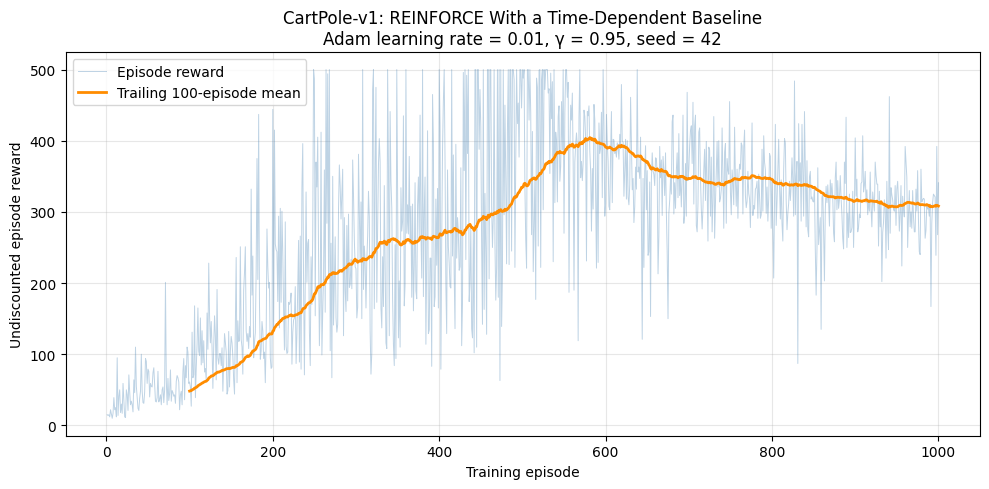

Final batch gradient norm: 4.439812e-03

Checkpoint | Mean reward | Sample SD | Reached 500
-----------------------------------------------------------
       200 |      172.66 |     79.65 |       0.0%
       400 |      297.72 |    139.51 |      16.0%
       600 |      382.12 |     78.67 |      10.0%
       800 |      335.40 |     49.94 |       0.0%
      1000 |      307.56 |     51.84 |       0.0%


In [ ]:
baseline_run_dir = Path(
    "cartpole_runs/time_baseline_seed42_lr001"
)

# 1. Required learning curve.
baseline_data = np.genfromtxt(
    baseline_run_dir / "training.csv",
    delimiter=",",
    names=True
)

baseline_rewards = baseline_data["reward"]
baseline_episodes = baseline_data["episode"].astype(int)

baseline_moving_average = np.convolve(
    baseline_rewards,
    np.ones(100) / 100,
    mode="valid"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    baseline_episodes,
    baseline_rewards,
    color="steelblue",
    alpha=0.35,
    linewidth=0.7,
    label="Episode reward"
)

ax.plot(
    baseline_episodes[99:],
    baseline_moving_average,
    color="darkorange",
    linewidth=2,
    label="Trailing 100-episode mean"
)

ax.set_xlabel("Training episode")
ax.set_ylabel("Undiscounted episode reward")
ax.set_title(
    "CartPole-v1: REINFORCE With a Time-Dependent Baseline\n"
    "Adam learning rate = 0.01, γ = 0.95, seed = 42"
)

ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    baseline_run_dir / "learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Show the final gradient norm without rounding it to two decimals.
print(
    "Final batch gradient norm:",
    f"{baseline_data['batch_gradient_norm'][-1]:.6e}"
)

# 2. Frozen-policy validation using the same validation seeds as before.
with torch.random.fork_rng(devices=[]):
    baseline_validation_policy = CartPolePolicy().to(cp_device)

baseline_validation_rows = []

print("\nCheckpoint | Mean reward | Sample SD | Reached 500")
print("-" * 59)

for checkpoint_episode in [200, 400, 600, 800, 1000]:
    checkpoint = torch.load(
        baseline_run_dir / f"checkpoint_{checkpoint_episode:04d}.pt",
        map_location=cp_device,
        weights_only=True
    )

    baseline_validation_policy.load_state_dict(
        checkpoint["policy_state_dict"]
    )

    scores = evaluate_cartpole_policy(
        baseline_validation_policy,
        n_episodes=50,
        environment_seed_start=7_000_000,
        action_seed=70_001
    )

    mean_score = float(scores.mean())
    sd_score = float(scores.std(ddof=1))
    success_rate = float(np.mean(scores == 500))

    baseline_validation_rows.append([
        checkpoint_episode,
        mean_score,
        sd_score,
        success_rate
    ])

    np.savetxt(
        baseline_run_dir
        / f"validation_scores_{checkpoint_episode:04d}.csv",
        scores,
        delimiter=",",
        header="episode_reward",
        comments=""
    )

    print(
        f"{checkpoint_episode:10d} | "
        f"{mean_score:11.2f} | "
        f"{sd_score:9.2f} | "
        f"{success_rate:10.1%}",
        flush=True
    )

np.savetxt(
    baseline_run_dir / "checkpoint_validation_summary.csv",
    np.asarray(baseline_validation_rows),
    delimiter=",",
    header="checkpoint_episode,mean_reward,sample_sd,fraction_reaching_500",
    comments="",
    fmt=["%d", "%.6f", "%.6f", "%.6f"]
)

FINAL EVALUATION: CARTPOLE WITH A BASELINE
Selected learning rate: 0.01
Selected checkpoint: episode 600
Evaluation episodes: 500
Mean reward: 376.36
Sample standard deviation: 66.56
Approximate 95% CI for mean: [370.52, 382.19]
Minimum reward: 100
Maximum reward: 500
Episodes reaching 500 steps: 2.6%


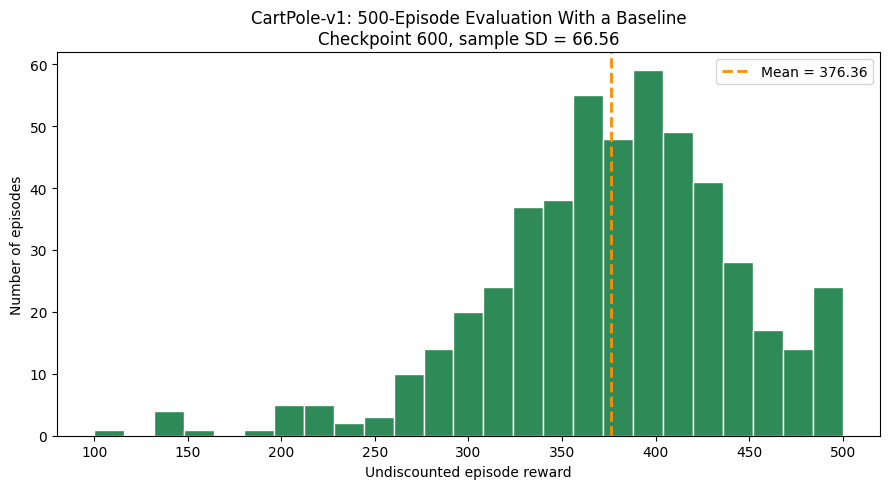

Evaluation files saved in: cartpole_runs/time_baseline_seed42_lr001/final_evaluation_checkpoint0600


In [ ]:
baseline_selected_dir = Path(
    "cartpole_runs/time_baseline_seed42_lr001"
)
baseline_selected_path = (
    baseline_selected_dir / "checkpoint_0600.pt"
)

baseline_final_dir = (
    baseline_selected_dir / "final_evaluation_checkpoint0600"
)

if baseline_final_dir.exists():
    raise FileExistsError(
        "This evaluation folder already exists. "
        "Stop and send me the message so we preserve the results."
    )

baseline_final_dir.mkdir(parents=True)

with torch.random.fork_rng(devices=[]):
    cp_baseline_selected_policy = CartPolePolicy().to(cp_device)

baseline_selected_checkpoint = torch.load(
    baseline_selected_path,
    map_location=cp_device,
    weights_only=True
)

cp_baseline_selected_policy.load_state_dict(
    baseline_selected_checkpoint["policy_state_dict"]
)

# No training or baseline updates occur during evaluation.
baseline_final_scores = evaluate_cartpole_policy(
    cp_baseline_selected_policy,
    n_episodes=500,
    environment_seed_start=9_000_000,
    action_seed=90_001
)

baseline_final_mean = float(baseline_final_scores.mean())
baseline_final_sd = float(baseline_final_scores.std(ddof=1))
baseline_final_se = baseline_final_sd / np.sqrt(
    len(baseline_final_scores)
)

baseline_ci_low = baseline_final_mean - 1.96 * baseline_final_se
baseline_ci_high = baseline_final_mean + 1.96 * baseline_final_se
baseline_success_rate = float(
    np.mean(baseline_final_scores == 500)
)

print("FINAL EVALUATION: CARTPOLE WITH A BASELINE")
print("Selected learning rate: 0.01")
print("Selected checkpoint: episode 600")
print("Evaluation episodes:", len(baseline_final_scores))
print(f"Mean reward: {baseline_final_mean:.2f}")
print(f"Sample standard deviation: {baseline_final_sd:.2f}")
print(
    f"Approximate 95% CI for mean: "
    f"[{baseline_ci_low:.2f}, {baseline_ci_high:.2f}]"
)
print(f"Minimum reward: {baseline_final_scores.min():.0f}")
print(f"Maximum reward: {baseline_final_scores.max():.0f}")
print(f"Episodes reaching 500 steps: {baseline_success_rate:.1%}")

# Required histogram.
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    baseline_final_scores,
    bins=25,
    color="seagreen",
    edgecolor="white"
)

ax.axvline(
    baseline_final_mean,
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label=f"Mean = {baseline_final_mean:.2f}"
)

ax.set_xlabel("Undiscounted episode reward")
ax.set_ylabel("Number of episodes")
ax.set_title(
    "CartPole-v1: 500-Episode Evaluation With a Baseline\n"
    f"Checkpoint 600, sample SD = {baseline_final_sd:.2f}"
)

ax.legend()
fig.tight_layout()
fig.savefig(
    baseline_final_dir / "reward_histogram.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save raw measurements.
np.savetxt(
    baseline_final_dir / "episode_scores.csv",
    np.column_stack([
        np.arange(9_000_000, 9_000_500),
        baseline_final_scores
    ]),
    delimiter=",",
    header="environment_seed,episode_reward",
    comments="",
    fmt=["%d", "%.1f"]
)

baseline_evaluation_summary = {
    "environment": "CartPole-v1",
    "checkpoint": str(baseline_selected_path),
    "baseline": "lagged time-dependent EMA",
    "selection_rule": (
        "Highest mean reward over 50 validation episodes among "
        "checkpoints 200, 400, 600, 800, 1000; "
        "learning rate 0.01; training seed 42."
    ),
    "evaluation_episodes": 500,
    "environment_seed_start": 9_000_000,
    "action_seed": 90_001,
    "action_selection": "sampled from frozen policy",
    "mean_reward": baseline_final_mean,
    "sample_standard_deviation": baseline_final_sd,
    "mean_confidence_interval_95": [
        baseline_ci_low, baseline_ci_high
    ],
    "fraction_reaching_500": baseline_success_rate
}

(baseline_final_dir / "summary.json").write_text(
    json.dumps(baseline_evaluation_summary, indent=2)
)

print("Evaluation files saved in:", baseline_final_dir)

In [ ]:
# Direct gradient-variance experiment.
variance_dir = Path(
    "cartpole_runs/time_baseline_seed42_lr001/gradient_variance"
)
variance_dir.mkdir(parents=True, exist_ok=True)

variance_checkpoint_path = Path(
    "cartpole_runs/time_baseline_seed42_lr001/checkpoint_0600.pt"
)

variance_checkpoint = torch.load(
    variance_checkpoint_path,
    map_location=cp_device,
    weights_only=True
)

with torch.random.fork_rng(devices=[]):
    variance_policy = CartPolePolicy().to(cp_device)

variance_policy.load_state_dict(
    variance_checkpoint["policy_state_dict"]
)
variance_policy.eval()

saved_baseline = (
    variance_checkpoint["time_baseline"]
    .cpu().numpy().copy()
)

variance_gamma = variance_checkpoint["config"]["gamma"]
N_VARIANCE_EPISODES = 100

gradients_without_baseline = []
gradients_with_baseline = []


def episode_gradient_vector(policy, episode, baseline=None):
    """Recompute log probabilities and return one episode's loss gradient."""
    states = torch.as_tensor(
        episode["states"],
        dtype=torch.float32,
        device=cp_device
    )
    actions = torch.as_tensor(
        episode["actions"],
        dtype=torch.long,
        device=cp_device
    )

    distribution = Categorical(logits=policy(states))
    log_probs = distribution.log_prob(actions)

    if baseline is None:
        loss = reinforce_loss(
            log_probs, episode["rewards"], variance_gamma
        )
    else:
        loss = reinforce_loss_with_baseline(
            log_probs, episode["rewards"],
            variance_gamma, baseline
        )

    # Computes gradients without applying updates or accumulating .grad.
    gradients = torch.autograd.grad(
        loss, tuple(policy.parameters())
    )

    return (
        torch.cat([gradient.reshape(-1) for gradient in gradients])
        .detach().cpu().numpy().astype(np.float64)
    )


variance_env = gym.make("CartPole-v1")

try:
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(80_001)

        for episode_index in range(N_VARIANCE_EPISODES):
            # Sample a fresh trajectory without keeping its computation graph.
            with torch.no_grad():
                episode = collect_cartpole_episode(
                    variance_env,
                    variance_policy,
                    reset_seed=8_000_000 + episode_index
                )

            # Two gradient calculations on exactly the same trajectory.
            gradients_without_baseline.append(
                episode_gradient_vector(
                    variance_policy, episode, baseline=None
                )
            )
            gradients_with_baseline.append(
                episode_gradient_vector(
                    variance_policy, episode, baseline=saved_baseline
                )
            )

            if (episode_index + 1) % 25 == 0:
                print(
                    f"Processed {episode_index + 1}/"
                    f"{N_VARIANCE_EPISODES} episodes",
                    flush=True
                )
finally:
    variance_env.close()

G_without = np.stack(gradients_without_baseline)
G_with = np.stack(gradients_with_baseline)

# Sum of the sample variances of all 898 gradient components.
# This equals the trace of the sample covariance matrix.
variance_without = float(G_without.var(axis=0, ddof=1).sum())
variance_with = float(G_with.var(axis=0, ddof=1).sum())

variance_ratio = (
    variance_with / variance_without
    if variance_without > 0 else None
)

print("\nFROZEN-POLICY GRADIENT VARIANCE")
print("Checkpoint: baseline model, episode 600")
print("Independent trajectories:", N_VARIANCE_EPISODES)
print(f"Without baseline: {variance_without:.6e}")
print(f"With baseline:    {variance_with:.6e}")

if variance_ratio is not None:
    print(f"Variance ratio (with / without): {variance_ratio:.6e}")
    print(f"Estimated reduction: {100 * (1 - variance_ratio):.6f}%")
else:
    print("Variance ratio undefined: no-baseline variance is zero.")

np.savez_compressed(
    variance_dir / "paired_episode_gradients.npz",
    without_baseline=G_without,
    with_baseline=G_with
)

variance_summary = {
    "checkpoint": str(variance_checkpoint_path),
    "episodes": N_VARIANCE_EPISODES,
    "environment_seed_start": 8_000_000,
    "action_seed": 80_001,
    "measurement": "trace of sample gradient covariance, ddof=1",
    "variance_without_baseline": variance_without,
    "variance_with_baseline": variance_with,
    "variance_ratio": variance_ratio,
    "same_policy_and_trajectories": True,
    "parameter_updates": 0
}

(variance_dir / "summary.json").write_text(
    json.dumps(variance_summary, indent=2)
)

print("Gradient measurements saved in:", variance_dir)

Processed 25/100 episodes
Processed 50/100 episodes
Processed 75/100 episodes
Processed 100/100 episodes

FROZEN-POLICY GRADIENT VARIANCE
Checkpoint: baseline model, episode 600
Independent trajectories: 100
Without baseline: 2.032806e+04
With baseline:    2.721566e-01
Variance ratio (with / without): 1.338822e-05
Estimated reduction: 99.998661%
Gradient measurements saved in: cartpole_runs/time_baseline_seed42_lr001/gradient_variance


In [ ]:
import zipfile
from pathlib import Path

cartpole_folder = Path("cartpole_runs")
cartpole_archive = Path("cartpole_results.zip")

if not cartpole_folder.exists():
    raise FileNotFoundError("The cartpole_runs folder was not found.")

# Include the preliminary random-agent reference.
random_reference_path = (
    Path("results") / "cartpole_random_reference.csv"
)

with zipfile.ZipFile(
    cartpole_archive,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in sorted(cartpole_folder.rglob("*")):
        if file_path.is_file():
            archive.write(file_path, arcname=str(file_path))

    if random_reference_path.exists():
        archive.write(
            random_reference_path,
            arcname=str(random_reference_path)
        )

with zipfile.ZipFile(cartpole_archive) as archive:
    saved_files = archive.namelist()

print("Created:", cartpole_archive)
print("Files included:", len(saved_files))
print(
    "Archive size:",
    f"{cartpole_archive.stat().st_size / (1024**2):.2f} MB"
)

print("\nFinal evaluation summaries:")
for filename in saved_files:
    if "final_evaluation" in filename and filename.endswith("summary.json"):
        print("-", filename)

print("\nGradient-variance summary:")
for filename in saved_files:
    if "gradient_variance" in filename and filename.endswith("summary.json"):
        print("-", filename)

Created: cartpole_results.zip
Files included: 51
Archive size: 2.50 MB

Final evaluation summaries:
- cartpole_runs/no_baseline_seed42_lr001/final_evaluation_checkpoint0800/summary.json
- cartpole_runs/time_baseline_seed42_lr001/final_evaluation_checkpoint0600/summary.json

Gradient-variance summary:
- cartpole_runs/time_baseline_seed42_lr001/gradient_variance/summary.json


# Pong-v5 — Policy Gradient

In [ ]:
%pip install -q ale-py

In [ ]:
import gymnasium as gym
import ale_py
import numpy as np
import torch

gym.register_envs(ale_py)

PONG_ACTIONS = (2, 3)
PONG_GAMMA = 0.99


def make_pong_env():
    return gym.make(
        "ALE/Pong-v5",
        obs_type="rgb",
        frameskip=4,
        repeat_action_probability=0.25,
        full_action_space=False
    )


pong_check_env = make_pong_env()

try:
    frame, info = pong_check_env.reset(seed=42)
    action_meanings = pong_check_env.unwrapped.get_action_meanings()

    print("ALE version:", ale_py.__version__)
    print("Environment:", pong_check_env.spec.id)
    print("Frame shape:", frame.shape)
    print("Frame dtype:", frame.dtype)
    print("Native number of actions:", pong_check_env.action_space.n)
    print("Native action meanings:", action_meanings)

    print("\nActions our policy will use:")
    for policy_action, environment_action in enumerate(PONG_ACTIONS):
        print(
            f"Policy output {policy_action} -> "
            f"environment action {environment_action} "
            f"({action_meanings[environment_action]})"
        )

    assert [action_meanings[a] for a in PONG_ACTIONS] == [
        "RIGHT", "LEFT"
    ]

    print("\nPyTorch version:", torch.__version__)
    print("CUDA GPU available:", torch.cuda.is_available())
    print("Pong setup successful!")

finally:
    pong_check_env.close()

ALE version: 0.12.1
Environment: ALE/Pong-v5
Frame shape: (210, 160, 3)
Frame dtype: uint8
Native number of actions: 6
Native action meanings: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']

Actions our policy will use:
Policy output 0 -> environment action 2 (RIGHT)
Policy output 1 -> environment action 3 (LEFT)

PyTorch version: 2.11.0+cpu
CUDA GPU available: False
Pong setup successful!


Processed shape: (80, 80)
Processed dtype: float32
Processed pixel values: [0. 1.]
Difference pixel values: [-1.  0.  1.]
Original RGB frame unchanged: True
Moving object detected in central play area: True


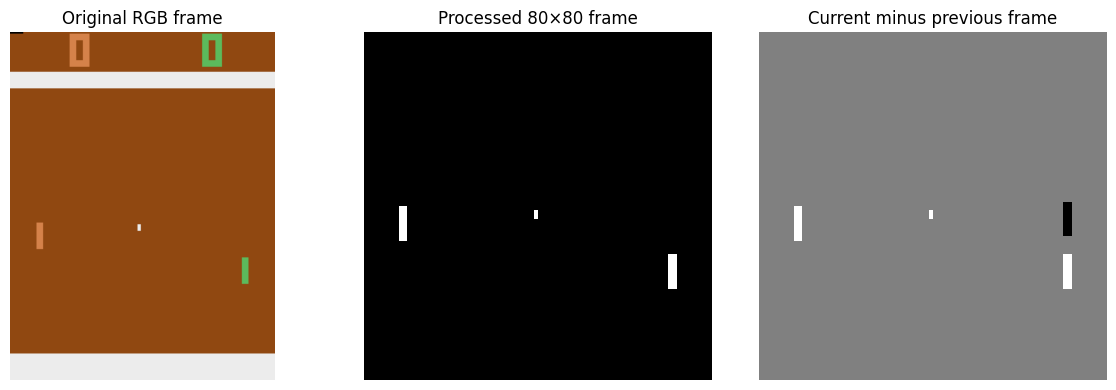

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path


def preprocess_pong(image):
    """Assignment preprocessing: RGB frame -> 80x80 binary image."""
    # Copy so preprocessing does not alter the original observation.
    processed = image[35:195].copy()
    processed = processed[::2, ::2, 0]

    processed[processed == 144] = 0
    processed[processed == 109] = 0
    processed[processed != 0] = 1

    return processed.astype(np.float32).reshape(80, 80)


pong_figure_dir = Path("pong_results/figures")
pong_figure_dir.mkdir(parents=True, exist_ok=True)

inspection_env = make_pong_env()
inspection_rng = np.random.default_rng(42)

moving_ball_found = False

try:
    frame, _ = inspection_env.reset(seed=42)
    previous_processed = preprocess_pong(frame)

    # Find a useful diagnostic frame with movement in the central
    # play area, excluding the paddle columns.
    for step in range(2_000):
        action = int(inspection_rng.choice(PONG_ACTIONS))

        frame, reward, terminated, truncated, _ = inspection_env.step(
            action
        )

        current_processed = preprocess_pong(frame)
        frame_difference = current_processed - previous_processed

        central_object_visible = np.any(
            current_processed[:, 10:70] != 0
        )
        central_movement_visible = np.any(
            frame_difference[:, 10:70] != 0
        )

        if central_object_visible and central_movement_visible:
            moving_ball_found = True
            break

        if terminated or truncated:
            frame, _ = inspection_env.reset(seed=43 + step)
            previous_processed = preprocess_pong(frame)
        else:
            previous_processed = current_processed

    if not moving_ball_found:
        raise RuntimeError(
            "No suitable moving-ball frame found. Send me this error."
        )

    # Confirm that preprocessing leaves the input unchanged.
    original_frame_copy = frame.copy()
    _ = preprocess_pong(frame)

    print("Processed shape:", current_processed.shape)
    print("Processed dtype:", current_processed.dtype)
    print("Processed pixel values:", np.unique(current_processed))
    print("Difference pixel values:", np.unique(frame_difference))
    print(
        "Original RGB frame unchanged:",
        bool(np.array_equal(frame, original_frame_copy))
    )
    print("Moving object detected in central play area:", moving_ball_found)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(frame)
    axes[0].set_title("Original RGB frame")

    axes[1].imshow(
        current_processed, cmap="gray", vmin=0, vmax=1
    )
    axes[1].set_title("Processed 80×80 frame")

    axes[2].imshow(
        frame_difference, cmap="gray", vmin=-1, vmax=1
    )
    axes[2].set_title("Current minus previous frame")

    for ax in axes:
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(
        pong_figure_dir / "preprocessing_check.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

finally:
    inspection_env.close()

In [ ]:
import time
import csv
from pathlib import Path

pong_results_dir = Path("pong_results")
pong_results_dir.mkdir(exist_ok=True)

pong_random_rng = np.random.default_rng(24680)
pong_random_env = make_pong_env()
pong_random_rows = []

print("Episode | Score | Steps | First reward step | Truncated")
print("-" * 65)

pong_reference_start = time.time()

try:
    for episode_index in range(10):
        frame, _ = pong_random_env.reset(
            seed=1_000_000 + episode_index
        )

        total_reward = 0.0
        steps = 0
        scoring_events = 0
        first_reward_step = None

        while True:
            # Exactly the two actions permitted by the assignment.
            action = int(pong_random_rng.choice(PONG_ACTIONS))

            frame, reward, terminated, truncated, _ = (
                pong_random_env.step(action)
            )

            steps += 1
            total_reward += float(reward)

            if reward != 0:
                scoring_events += 1

                if first_reward_step is None:
                    first_reward_step = steps

            if terminated or truncated:
                break

        pong_random_rows.append({
            "episode": episode_index + 1,
            "environment_seed": 1_000_000 + episode_index,
            "score": total_reward,
            "steps": steps,
            "first_reward_step": first_reward_step,
            "scoring_events": scoring_events,
            "terminated": bool(terminated),
            "truncated": bool(truncated)
        })

        print(
            f"{episode_index + 1:7d} | "
            f"{total_reward:5.0f} | "
            f"{steps:5d} | "
            f"{str(first_reward_step):17s} | "
            f"{str(bool(truncated))}",
            flush=True
        )

finally:
    pong_random_env.close()

pong_reference_seconds = time.time() - pong_reference_start
pong_random_scores = np.array([
    row["score"] for row in pong_random_rows
])

with (pong_results_dir / "random_reference.csv").open(
    "w", newline=""
) as file:
    writer = csv.DictWriter(
        file, fieldnames=list(pong_random_rows[0].keys())
    )
    writer.writeheader()
    writer.writerows(pong_random_rows)

print("\nRANDOM-ACTION PONG REFERENCE")
print(f"Mean score: {pong_random_scores.mean():.2f}")
print(f"Sample standard deviation: {pong_random_scores.std(ddof=1):.2f}")
print(
    "Mean steps per episode:",
    f"{np.mean([row['steps'] for row in pong_random_rows]):.1f}"
)
print(
    "Truncated episodes:",
    sum(row["truncated"] for row in pong_random_rows)
)
print(f"Total elapsed time: {pong_reference_seconds:.1f} seconds")
print(
    "Seconds per episode:",
    f"{pong_reference_seconds / len(pong_random_rows):.2f}"
)

Episode | Score | Steps | First reward step | Truncated
-----------------------------------------------------------------
      1 |   -21 |   946 | 64                | False
      2 |   -20 |   982 | 64                | False
      3 |   -21 |  1005 | 64                | False
      4 |   -21 |   947 | 64                | False
      5 |   -21 |   887 | 64                | False
      6 |   -20 |  1041 | 124               | False
      7 |   -20 |  1102 | 64                | False
      8 |   -20 |  1102 | 64                | False
      9 |   -21 |   885 | 64                | False
     10 |   -21 |   824 | 64                | False

RANDOM-ACTION PONG REFERENCE
Mean score: -20.60
Sample standard deviation: 0.52
Mean steps per episode: 972.1
Truncated episodes: 0
Total elapsed time: 22.0 seconds
Seconds per episode: 2.20


In [ ]:
import torch
import torch.nn as nn
from torch.distributions import Categorical
import numpy as np
import time

PONG_SEED = 42
pong_device = torch.device("cpu")


class PongPolicy(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(80 * 80, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, observation):
        return self.network(observation)


@torch.no_grad()
def collect_pong_episode(env, policy, reset_seed):
    frame, _ = env.reset(seed=reset_seed)

    # Reset frame history at the beginning of EVERY episode.
    previous_frame = None

    observations = []
    actions = []
    rewards = []

    while True:
        current_frame = preprocess_pong(frame)

        if previous_frame is None:
            observation = np.zeros(6400, dtype=np.float32)
        else:
            observation = (
                current_frame - previous_frame
            ).reshape(-1)

        previous_frame = current_frame

        observation_tensor = torch.as_tensor(
            observation,
            dtype=torch.float32,
            device=pong_device
        )

        distribution = Categorical(
            logits=policy(observation_tensor)
        )

        # Policy actions 0/1 map to environment actions 2/3.
        policy_action = int(distribution.sample().item())
        environment_action = PONG_ACTIONS[policy_action]

        frame, reward, terminated, truncated, _ = env.step(
            environment_action
        )

        # Differences are -1, 0, or 1, so int8 stores them exactly.
        observations.append(observation.astype(np.int8))
        actions.append(policy_action)
        rewards.append(float(reward))

        if terminated or truncated:
            break

    return {
        "observations": np.stack(observations),
        "actions": np.asarray(actions, dtype=np.int64),
        "rewards": np.asarray(rewards, dtype=np.float64),
        "terminated": bool(terminated),
        "truncated": bool(truncated)
    }


torch.set_num_threads(1)
torch.manual_seed(PONG_SEED)

pong_policy = PongPolicy().to(pong_device)

print(pong_policy)
print(
    "\nTrainable parameters:",
    sum(p.numel() for p in pong_policy.parameters())
)

# One diagnostic episode; no training or parameter updates.
pong_diagnostic_env = make_pong_env()
diagnostic_start = time.time()

try:
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(24681)

        pong_diagnostic_episode = collect_pong_episode(
            pong_diagnostic_env,
            pong_policy,
            reset_seed=2_000_000
        )
finally:
    pong_diagnostic_env.close()

diagnostic_seconds = time.time() - diagnostic_start

print("\nUNTRAINED NETWORK: ONE EPISODE")
print("Score:", pong_diagnostic_episode["rewards"].sum())
print("Steps:", len(pong_diagnostic_episode["rewards"]))
print(
    "Stored observation shape:",
    pong_diagnostic_episode["observations"].shape
)
print(
    "First frame difference is zero:",
    bool(np.all(
        pong_diagnostic_episode["observations"][0] == 0
    ))
)
print(
    "Policy action counts [0, 1]:",
    np.bincount(pong_diagnostic_episode["actions"], minlength=2)
)
print("Terminated:", pong_diagnostic_episode["terminated"])
print("Truncated:", pong_diagnostic_episode["truncated"])
print(f"Collection time: {diagnostic_seconds:.2f} seconds")
print(
    "Observation storage:",
    f"{pong_diagnostic_episode['observations'].nbytes / 1024**2:.2f} MB"
)
print("No network weights were updated.")

PongPolicy(
  (network): Sequential(
    (0): Linear(in_features=6400, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=2, bias=True)
  )
)

Trainable parameters: 819586

UNTRAINED NETWORK: ONE EPISODE
Score: -21.0
Steps: 826
Stored observation shape: (826, 6400)
First frame difference is zero: True
Policy action counts [0, 1]: [435 391]
Terminated: True
Truncated: False
Collection time: 5.24 seconds
Observation storage: 5.04 MB
No network weights were updated.


In [ ]:
def accumulate_pong_gradient(
    policy,
    episode,
    gamma,
    baseline=None,
    episode_divisor=1,
    chunk_size=256
):
    """
    Accumulate one episode's REINFORCE loss gradients.

    The caller must:
    1. Clear gradients before the training batch.
    2. Keep weights unchanged while collecting that batch.
    3. Apply the optimizer update only after all gradients accumulate.
    """
    returns = discounted_returns(episode["rewards"], gamma)

    if baseline is None:
        advantages = returns
    else:
        advantages = returns - baseline[:len(returns)]

    # Exact start-of-episode discounted objective.
    coefficients = (
        gamma ** np.arange(len(returns))
    ) * advantages

    total_loss = 0.0

    for start in range(0, len(returns), chunk_size):
        stop = min(start + chunk_size, len(returns))

        observations = torch.as_tensor(
            episode["observations"][start:stop],
            dtype=torch.float32,
            device=pong_device
        )
        actions = torch.as_tensor(
            episode["actions"][start:stop],
            dtype=torch.long,
            device=pong_device
        )
        weights = torch.as_tensor(
            coefficients[start:stop],
            dtype=torch.float32,
            device=pong_device
        )

        distribution = Categorical(logits=policy(observations))
        log_probs = distribution.log_prob(actions)

        chunk_loss = (
            -(weights * log_probs).sum() / episode_divisor
        )
        chunk_loss.backward()

        total_loss += float(chunk_loss.detach().cpu())

    return total_loss


def flatten_pong_gradients(policy):
    return torch.cat([
        parameter.grad.reshape(-1)
        for parameter in policy.parameters()
        if parameter.grad is not None
    ]).detach().clone()


# 1. Compute gradients in chunks.
pong_policy.zero_grad(set_to_none=True)
gradient_start = time.time()

chunked_loss = accumulate_pong_gradient(
    pong_policy,
    pong_diagnostic_episode,
    gamma=PONG_GAMMA,
    chunk_size=256
)

chunked_gradient = flatten_pong_gradients(pong_policy)
chunked_seconds = time.time() - gradient_start

# 2. Independently recompute using one full-episode chunk.
# This is manageable for our short diagnostic episode.
pong_policy.zero_grad(set_to_none=True)

full_episode_loss = accumulate_pong_gradient(
    pong_policy,
    pong_diagnostic_episode,
    gamma=PONG_GAMMA,
    chunk_size=len(pong_diagnostic_episode["rewards"])
)

full_episode_gradient = flatten_pong_gradients(pong_policy)

gradient_difference = (
    chunked_gradient - full_episode_gradient
).norm().item()

reference_norm = full_episode_gradient.norm().item()

relative_difference = (
    gradient_difference / max(reference_norm, 1e-12)
)

diagnostic_returns = discounted_returns(
    pong_diagnostic_episode["rewards"],
    PONG_GAMMA
)

print("PONG GRADIENT CHECK")
print(f"Chunked loss: {chunked_loss:.6f}")
print(f"Full-episode loss: {full_episode_loss:.6f}")
print(f"Chunked gradient norm: {chunked_gradient.norm().item():.6e}")
print(
    "All gradient components finite:",
    bool(torch.isfinite(chunked_gradient).all().item())
)
print(f"Relative gradient difference: {relative_difference:.6e}")
print(
    "Gradients agree within relative tolerance 1e-5:",
    relative_difference < 1e-5
)
print(f"Chunked gradient calculation time: {chunked_seconds:.2f} seconds")

print("\nDISCOUNTED OBJECTIVE")
print(f"Episode score: {pong_diagnostic_episode['rewards'].sum():.1f}")
print(f"Starting discounted return: {diagnostic_returns[0]:.6f}")
print(f"Weight on timestep 500: {PONG_GAMMA**500:.6f}")

# Clear diagnostic gradients without changing the network weights.
pong_policy.zero_grad(set_to_none=True)
print("\nNo optimizer update performed.")

PONG GRADIENT CHECK
Chunked loss: -181.292125
Full-episode loss: -181.292130
Chunked gradient norm: 2.741663e+01
All gradient components finite: True
Relative gradient difference: 6.907526e-08
Gradients agree within relative tolerance 1e-5: True
Chunked gradient calculation time: 0.28 seconds

DISCOUNTED OBJECTIVE
Episode score: -21.0
Starting discounted return: -1.788626
Weight on timestep 500: 0.006570

No optimizer update performed.


In [ ]:
import csv
import json
import time
from pathlib import Path

PONG_TRAIN_EPISODES = 100
PONG_BATCH_SIZE = 4
PONG_LEARNING_RATE = 0.01
PONG_TRAIN_SEED = 42

pong_run_dir = Path(
    "pong_runs/no_baseline_seed42_lr001"
)

if pong_run_dir.exists():
    raise FileExistsError(
        f"{pong_run_dir} already exists. "
        "Stop and send me the message so we preserve the run."
    )

pong_run_dir.mkdir(parents=True)

torch.set_num_threads(1)
torch.manual_seed(PONG_TRAIN_SEED)

# Fresh initialization: diagnostic calculations do not carry over.
pong_policy = PongPolicy().to(pong_device)
pong_optimizer = torch.optim.Adam(
    pong_policy.parameters(),
    lr=PONG_LEARNING_RATE
)

pong_config = {
    "environment": "ALE/Pong-v5",
    "seed": PONG_TRAIN_SEED,
    "episodes": PONG_TRAIN_EPISODES,
    "batch_size": PONG_BATCH_SIZE,
    "learning_rate": PONG_LEARNING_RATE,
    "gamma": PONG_GAMMA,
    "baseline": None,
    "return_normalization": False,
    "point_boundary_return_reset": False,
    "policy_actions": [2, 3],
    "observation": "difference of consecutive preprocessed 80x80 frames",
    "frameskip": 4,
    "repeat_action_probability": 0.25,
    "hidden_units": 128,
    "activation": "ReLU",
    "gradient_chunk_size": 256,
    "loss": "-sum_t gamma^t * G_t * log_prob_t",
    "device": str(pong_device),
    "gymnasium_version": gym.__version__,
    "ale_version": ale_py.__version__,
    "torch_version": str(torch.__version__),
    "environment_seed_start": 3_000_000
}

(pong_run_dir / "config.json").write_text(
    json.dumps(pong_config, indent=2)
)

pong_training_scores = []
pong_train_env = make_pong_env()
pong_training_start = time.time()

try:
    with (pong_run_dir / "training.csv").open(
        "w", newline=""
    ) as log_file:
        writer = csv.writer(log_file)
        writer.writerow([
            "episode", "environment_seed", "reward",
            "discounted_return", "length",
            "points_won", "points_lost",
            "fraction_action_2",
            "terminated", "truncated",
            "batch_gradient_norm", "elapsed_seconds"
        ])

        for batch_start in range(
            0, PONG_TRAIN_EPISODES, PONG_BATCH_SIZE
        ):
            batch_end = min(
                batch_start + PONG_BATCH_SIZE,
                PONG_TRAIN_EPISODES
            )

            # Keep the policy unchanged throughout collection.
            batch = [
                collect_pong_episode(
                    pong_train_env,
                    pong_policy,
                    reset_seed=3_000_000 + episode_index
                )
                for episode_index in range(batch_start, batch_end)
            ]

            pong_optimizer.zero_grad(set_to_none=True)

            # Accumulate the average of full-episode gradients.
            # No parameter updates between episodes or chunks.
            for episode in batch:
                accumulate_pong_gradient(
                    pong_policy,
                    episode,
                    gamma=PONG_GAMMA,
                    baseline=None,
                    episode_divisor=len(batch),
                    chunk_size=256
                )

            grad_norm = torch.sqrt(sum(
                parameter.grad.square().sum()
                for parameter in pong_policy.parameters()
                if parameter.grad is not None
            ))

            if not torch.isfinite(grad_norm).item():
                raise FloatingPointError(
                    "Nonfinite gradient detected; training stopped."
                )

            pong_optimizer.step()

            for episode_index, episode in zip(
                range(batch_start, batch_end), batch
            ):
                rewards = episode["rewards"]
                score = float(rewards.sum())
                pong_training_scores.append(score)

                writer.writerow([
                    episode_index + 1,
                    3_000_000 + episode_index,
                    score,
                    discounted_returns(rewards, PONG_GAMMA)[0],
                    len(rewards),
                    int(np.sum(rewards > 0)),
                    int(np.sum(rewards < 0)),
                    float(np.mean(episode["actions"] == 0)),
                    episode["terminated"],
                    episode["truncated"],
                    grad_norm.item(),
                    time.time() - pong_training_start
                ])

            log_file.flush()

            if batch_end % 20 == 0:
                torch.save(
                    {
                        "completed_episodes": batch_end,
                        "policy_state_dict": pong_policy.state_dict(),
                        "optimizer_state_dict":
                            pong_optimizer.state_dict(),
                        "torch_rng_state": torch.get_rng_state(),
                        "config": pong_config
                    },
                    pong_run_dir / f"checkpoint_{batch_end:05d}.pt"
                )

                print(
                    f"Episode {batch_end:3d} | "
                    f"Last 20 mean score: "
                    f"{np.mean(pong_training_scores[-20:]):6.2f} | "
                    f"Gradient norm: {grad_norm.item():.3e} | "
                    f"Elapsed: "
                    f"{(time.time() - pong_training_start) / 60:.1f} min",
                    flush=True
                )

            # Release the stored episode observations.
            del batch

finally:
    pong_train_env.close()

print(
    f"\nPilot finished in "
    f"{(time.time() - pong_training_start) / 60:.1f} minutes"
)
print("Results saved in:", pong_run_dir)

Episode  20 | Last 20 mean score: -20.45 | Gradient norm: 1.100e+01 | Elapsed: 0.6 min
Episode  40 | Last 20 mean score: -20.90 | Gradient norm: 1.555e+01 | Elapsed: 1.1 min
Episode  60 | Last 20 mean score: -20.90 | Gradient norm: 1.441e+01 | Elapsed: 1.6 min
Episode  80 | Last 20 mean score: -21.00 | Gradient norm: 1.447e+01 | Elapsed: 2.2 min
Episode 100 | Last 20 mean score: -21.00 | Gradient norm: 1.197e+01 | Elapsed: 2.7 min

Pilot finished in 2.7 minutes
Results saved in: pong_runs/no_baseline_seed42_lr001


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

pilot_dir = Path("pong_runs/no_baseline_seed42_lr001")

# Locate the training CSV by its columns.
pilot_df = None
for csv_path in sorted(pilot_dir.glob("*.csv")):
    candidate = pd.read_csv(csv_path)
    required = {"episode", "reward", "fraction_action_2", "length"}
    if required.issubset(candidate.columns):
        pilot_df = candidate.sort_values("episode").reset_index(drop=True)
        print("Reading:", csv_path)
        break

if pilot_df is None:
    raise FileNotFoundError(
        "Could not find the training CSV. "
        f"Files present: {[p.name for p in pilot_dir.iterdir()]}"
    )

print("\nPONG PILOT DIAGNOSTICS")
print("Episodes logged:", len(pilot_df))

for label, block in [
    ("First 20 episodes", pilot_df.head(20)),
    ("Last 20 episodes", pilot_df.tail(20)),
]:
    # Weight by episode length to estimate the fraction across all actions.
    right_fraction = np.average(
        block["fraction_action_2"],
        weights=block["length"],
    )

    print(f"\n{label}")
    print(f"Mean score: {block['reward'].mean():.2f}")
    print(f"Mean episode length: {block['length'].mean():.1f}")
    print(f"Fraction RIGHT (action 2): {right_fraction:.4f}")
    print(f"Fraction LEFT  (action 3): {1 - right_fraction:.4f}")

    near_single_action = (
        (block["fraction_action_2"] <= 0.01)
        | (block["fraction_action_2"] >= 0.99)
    )
    print(
        "Episodes using one action at least 99% of the time:",
        f"{near_single_action.sum()}/{len(block)}",
    )

if {"points_won", "points_lost"}.issubset(pilot_df.columns):
    print("\nLast 20 episodes:")
    print("Total points won:", int(pilot_df.tail(20)["points_won"].sum()))
    print("Total points lost:", int(pilot_df.tail(20)["points_lost"].sum()))

print("\nNo training or parameter updates performed.")

Reading: pong_runs/no_baseline_seed42_lr001/training.csv

PONG PILOT DIAGNOSTICS
Episodes logged: 100

First 20 episodes
Mean score: -20.45
Mean episode length: 986.8
Fraction RIGHT (action 2): 0.4557
Fraction LEFT  (action 3): 0.5443
Episodes using one action at least 99% of the time: 0/20

Last 20 episodes
Mean score: -21.00
Mean episode length: 858.8
Fraction RIGHT (action 2): 0.3271
Fraction LEFT  (action 3): 0.6729
Episodes using one action at least 99% of the time: 0/20

Last 20 episodes:
Total points won: 0
Total points lost: 420

No training or parameter updates performed.


In [ ]:
import csv
import json
import time
from pathlib import Path

import numpy as np
import torch

# Separate experiment; preserve the original pilot.
pong_small_lr_dir = Path("pong_runs/no_baseline_seed42_lr0001")
if pong_small_lr_dir.exists():
    raise FileExistsError(
        f"{pong_small_lr_dir} already exists. "
        "Do not overwrite it; send me this message instead."
    )
pong_small_lr_dir.mkdir(parents=True)

# Copy the original configuration and change only the learning rate.
small_lr_config = dict(pong_config)
small_lr_config.update({
    "learning_rate": 0.001,
    "episodes": 100,
    "batch_size": 4,
    "seed": 42,
    "environment_seed_start": 3_000_000,
})

(pong_small_lr_dir / "config.json").write_text(
    json.dumps(small_lr_config, indent=2)
)

torch.set_num_threads(1)
torch.manual_seed(42)

pong_small_lr_policy = PongPolicy().to(pong_device)
pong_small_lr_optimizer = torch.optim.Adam(
    pong_small_lr_policy.parameters(), lr=0.001
)

small_lr_scores = []
small_lr_env = make_pong_env()
small_lr_start = time.time()

columns = [
    "episode", "environment_seed", "reward", "discounted_return",
    "length", "points_won", "points_lost", "fraction_action_2",
    "terminated", "truncated", "batch_gradient_norm", "elapsed_seconds",
]

try:
    with (pong_small_lr_dir / "training.csv").open(
        "w", newline=""
    ) as log_file:
        writer = csv.DictWriter(log_file, fieldnames=columns)
        writer.writeheader()

        for batch_start in range(0, 100, 4):
            batch = [
                collect_pong_episode(
                    small_lr_env,
                    pong_small_lr_policy,
                    reset_seed=3_000_000 + episode_index,
                )
                for episode_index in range(batch_start, batch_start + 4)
            ]

            pong_small_lr_optimizer.zero_grad(set_to_none=True)

            for episode in batch:
                accumulate_pong_gradient(
                    pong_small_lr_policy,
                    episode,
                    gamma=0.99,
                    baseline=None,
                    episode_divisor=len(batch),
                    chunk_size=256,
                )

            grad_norm = torch.sqrt(sum(
                parameter.grad.square().sum()
                for parameter in pong_small_lr_policy.parameters()
                if parameter.grad is not None
            )).item()

            if not np.isfinite(grad_norm):
                raise RuntimeError("Nonfinite gradient; training stopped.")

            pong_small_lr_optimizer.step()

            for offset, episode in enumerate(batch):
                episode_index = batch_start + offset
                rewards = np.asarray(episode["rewards"])
                score = float(rewards.sum())
                small_lr_scores.append(score)

                writer.writerow({
                    "episode": episode_index + 1,
                    "environment_seed": 3_000_000 + episode_index,
                    "reward": score,
                    "discounted_return": float(
                        discounted_returns(rewards, 0.99)[0]
                    ),
                    "length": len(rewards),
                    "points_won": int(np.sum(rewards > 0)),
                    "points_lost": int(np.sum(rewards < 0)),
                    "fraction_action_2": float(
                        np.mean(np.asarray(episode["actions"]) == 0)
                    ),
                    "terminated": episode["terminated"],
                    "truncated": episode["truncated"],
                    "batch_gradient_norm": grad_norm,
                    "elapsed_seconds": time.time() - small_lr_start,
                })

            log_file.flush()
            completed = batch_start + len(batch)

            if completed % 20 == 0:
                torch.save({
                    "completed_episodes": completed,
                    "policy_state_dict": pong_small_lr_policy.state_dict(),
                    "optimizer_state_dict":
                        pong_small_lr_optimizer.state_dict(),
                    "torch_rng_state": torch.get_rng_state(),
                    "config": small_lr_config,
                }, pong_small_lr_dir / f"checkpoint_{completed:05d}.pt")

                print(
                    f"Episode {completed:3d} | "
                    f"Last 20 mean score: "
                    f"{np.mean(small_lr_scores[-20:]):6.2f} | "
                    f"Gradient norm: {grad_norm:.3e} | "
                    f"Elapsed: {(time.time() - small_lr_start)/60:.1f} min"
                )

            del batch

finally:
    small_lr_env.close()

print("\nPilot complete.")
print("Results saved in:", pong_small_lr_dir)

Episode  20 | Last 20 mean score: -20.60 | Gradient norm: 1.252e+01 | Elapsed: 0.6 min
Episode  40 | Last 20 mean score: -20.50 | Gradient norm: 1.678e+01 | Elapsed: 1.2 min
Episode  60 | Last 20 mean score: -20.15 | Gradient norm: 1.094e+01 | Elapsed: 1.7 min
Episode  80 | Last 20 mean score: -20.55 | Gradient norm: 1.232e+01 | Elapsed: 2.3 min
Episode 100 | Last 20 mean score: -20.15 | Gradient norm: 1.154e+01 | Elapsed: 2.9 min

Pilot complete.
Results saved in: pong_runs/no_baseline_seed42_lr0001


In [ ]:
import csv
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

resume_dir = Path("pong_runs/no_baseline_seed42_lr0001")
resume_path = resume_dir / "checkpoint_00100.pt"
training_path = resume_dir / "training.csv"
target_episodes = 1000

# Prevent accidentally appending duplicate episodes.
existing_log = pd.read_csv(training_path)
if (
    len(existing_log) != 100
    or existing_log["episode"].tolist() != list(range(1, 101))
):
    raise RuntimeError(
        "Expected exactly episodes 1–100 in the log. "
        "Do not rerun this cell after a partial continuation; "
        "send me the output so we can resume safely."
    )

checkpoint = torch.load(
    resume_path, map_location=pong_device, weights_only=True
)
assert checkpoint["completed_episodes"] == 100

torch.set_num_threads(1)

continued_policy = PongPolicy().to(pong_device)
continued_policy.load_state_dict(checkpoint["policy_state_dict"])

continued_optimizer = torch.optim.Adam(
    continued_policy.parameters(), lr=0.001
)
continued_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Restore after creating the network, which consumes random numbers.
torch.set_rng_state(checkpoint["torch_rng_state"].cpu())

continued_config = dict(checkpoint["config"])
continued_config["episodes"] = target_episodes

(resume_dir / "continuation_config.json").write_text(
    json.dumps(continued_config, indent=2)
)

continued_scores = existing_log["reward"].astype(float).tolist()
previous_elapsed = float(existing_log["elapsed_seconds"].iloc[-1])
continuation_start = time.time()
continued_env = make_pong_env()

columns = existing_log.columns.tolist()

try:
    with training_path.open("a", newline="") as log_file:
        writer = csv.DictWriter(log_file, fieldnames=columns)

        for batch_start in range(100, target_episodes, 4):
            batch_end = min(batch_start + 4, target_episodes)

            batch = [
                collect_pong_episode(
                    continued_env,
                    continued_policy,
                    reset_seed=3_000_000 + episode_index,
                )
                for episode_index in range(batch_start, batch_end)
            ]

            continued_optimizer.zero_grad(set_to_none=True)

            for episode in batch:
                accumulate_pong_gradient(
                    continued_policy,
                    episode,
                    gamma=0.99,
                    baseline=None,
                    episode_divisor=len(batch),
                    chunk_size=256,
                )

            grad_norm = torch.sqrt(sum(
                parameter.grad.square().sum()
                for parameter in continued_policy.parameters()
                if parameter.grad is not None
            )).item()

            if not np.isfinite(grad_norm):
                raise RuntimeError("Nonfinite gradient; training stopped.")

            continued_optimizer.step()

            for offset, episode in enumerate(batch):
                episode_index = batch_start + offset
                rewards = np.asarray(episode["rewards"])
                score = float(rewards.sum())
                continued_scores.append(score)

                writer.writerow({
                    "episode": episode_index + 1,
                    "environment_seed": 3_000_000 + episode_index,
                    "reward": score,
                    "discounted_return": float(
                        discounted_returns(rewards, 0.99)[0]
                    ),
                    "length": len(rewards),
                    "points_won": int(np.sum(rewards > 0)),
                    "points_lost": int(np.sum(rewards < 0)),
                    "fraction_action_2": float(
                        np.mean(np.asarray(episode["actions"]) == 0)
                    ),
                    "terminated": episode["terminated"],
                    "truncated": episode["truncated"],
                    "batch_gradient_norm": grad_norm,
                    "elapsed_seconds": (
                        previous_elapsed
                        + time.time() - continuation_start
                    ),
                })

            log_file.flush()

            if batch_end % 100 == 0:
                torch.save({
                    "completed_episodes": batch_end,
                    "policy_state_dict": continued_policy.state_dict(),
                    "optimizer_state_dict": continued_optimizer.state_dict(),
                    "torch_rng_state": torch.get_rng_state(),
                    "config": continued_config,
                }, resume_dir / f"checkpoint_{batch_end:05d}.pt")

                print(
                    f"Episode {batch_end:4d} | "
                    f"Last 100 mean score: "
                    f"{np.mean(continued_scores[-100:]):6.2f} | "
                    f"Gradient norm: {grad_norm:.3e} | "
                    f"Additional time: "
                    f"{(time.time() - continuation_start)/60:.1f} min",
                    flush=True,
                )

            del batch

finally:
    continued_env.close()

print("\nContinuation finished.")
print("Total episodes:", len(continued_scores))
print("Results saved in:", resume_dir)

Episode  200 | Last 100 mean score: -20.45 | Gradient norm: 1.412e+01 | Additional time: 3.1 min
Episode  300 | Last 100 mean score: -20.49 | Gradient norm: 1.281e+01 | Additional time: 6.0 min
Episode  400 | Last 100 mean score: -20.58 | Gradient norm: 1.266e+01 | Additional time: 8.8 min
Episode  500 | Last 100 mean score: -20.42 | Gradient norm: 1.257e+01 | Additional time: 11.7 min
Episode  600 | Last 100 mean score: -20.47 | Gradient norm: 9.268e+00 | Additional time: 14.4 min
Episode  700 | Last 100 mean score: -20.75 | Gradient norm: 1.567e+01 | Additional time: 17.1 min
Episode  800 | Last 100 mean score: -20.77 | Gradient norm: 1.685e+01 | Additional time: 19.7 min
Episode  900 | Last 100 mean score: -20.86 | Gradient norm: 1.007e+01 | Additional time: 22.2 min
Episode 1000 | Last 100 mean score: -20.65 | Gradient norm: 1.512e+01 | Additional time: 24.9 min

Continuation finished.
Total episodes: 1000
Results saved in: pong_runs/no_baseline_seed42_lr0001


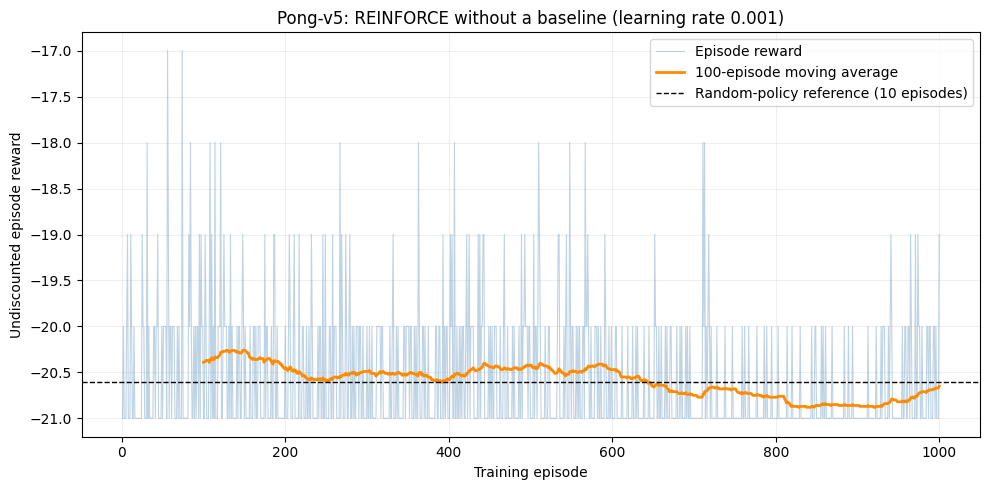

TRAINING DIAGNOSTICS

First 100 episodes
Mean episode reward: -20.390
Mean starting discounted return: -1.353645
Mean episode length: 1006.0
Fraction RIGHT across all actions: 0.5043
Points won: 61
Points lost: 2100

Last 100 episodes
Mean episode reward: -20.650
Mean starting discounted return: -1.214473
Mean episode length: 941.4
Fraction RIGHT across all actions: 0.4128
Points won: 35
Points lost: 2100

Highest 100-episode mean: -20.26
Window ending at episode: 128
Plot saved to: pong_runs/no_baseline_seed42_lr0001/learning_curve.png
No parameter updates performed.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pong_analysis_dir = Path("pong_runs/no_baseline_seed42_lr0001")
pong_log = pd.read_csv(pong_analysis_dir / "training.csv")

# Required plot: episode rewards and trailing 100-episode average.
moving_average = pong_log["reward"].rolling(
    window=100, min_periods=100
).mean()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    pong_log["episode"], pong_log["reward"],
    color="steelblue", alpha=0.35, linewidth=0.8,
    label="Episode reward",
)
ax.plot(
    pong_log["episode"], moving_average,
    color="darkorange", linewidth=2,
    label="100-episode moving average",
)
ax.axhline(
    -20.60, color="black", linestyle="--", linewidth=1,
    label="Random-policy reference (10 episodes)",
)

ax.set(
    title="Pong-v5: REINFORCE without a baseline (learning rate 0.001)",
    xlabel="Training episode",
    ylabel="Undiscounted episode reward",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

figure_path = pong_analysis_dir / "learning_curve.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# Diagnostics: compare equal-size windows.
print("TRAINING DIAGNOSTICS")
for label, block in [
    ("First 100", pong_log.head(100)),
    ("Last 100", pong_log.tail(100)),
]:
    right_fraction = np.average(
        block["fraction_action_2"], weights=block["length"]
    )

    print(f"\n{label} episodes")
    print(f"Mean episode reward: {block['reward'].mean():.3f}")
    print(
        "Mean starting discounted return:",
        f"{block['discounted_return'].mean():.6f}",
    )
    print(f"Mean episode length: {block['length'].mean():.1f}")
    print(f"Fraction RIGHT across all actions: {right_fraction:.4f}")
    print(f"Points won: {int(block['points_won'].sum())}")
    print(f"Points lost: {int(block['points_lost'].sum())}")

best_index = moving_average.idxmax()

training_summary = {
    "training_episodes": int(len(pong_log)),
    "first_100_mean_reward": float(pong_log.head(100)["reward"].mean()),
    "last_100_mean_reward": float(pong_log.tail(100)["reward"].mean()),
    "highest_100_episode_mean": float(moving_average.loc[best_index]),
    "highest_window_ending_episode":
        int(pong_log.loc[best_index, "episode"]),
    "first_100_mean_discounted_return":
        float(pong_log.head(100)["discounted_return"].mean()),
    "last_100_mean_discounted_return":
        float(pong_log.tail(100)["discounted_return"].mean()),
}

(pong_analysis_dir / "training_summary.json").write_text(
    json.dumps(training_summary, indent=2)
)

print(
    "\nHighest 100-episode mean:",
    f"{training_summary['highest_100_episode_mean']:.2f}",
)
print(
    "Window ending at episode:",
    training_summary["highest_window_ending_episode"],
)
print("Plot saved to:", figure_path)
print("No parameter updates performed.")

In [ ]:
import csv
import json
import time
from pathlib import Path

import numpy as np
import torch

pb_dir = Path("pong_runs/time_baseline_seed42_lr0001")
if pb_dir.exists():
    raise FileExistsError(
        f"{pb_dir} already exists. Send me this message before continuing."
    )

# Variable-length episodes: new timestep entries start at zero.
def extend_pong_baseline(baseline, required_length):
    if required_length <= len(baseline):
        return baseline
    return np.pad(baseline, (0, required_length - len(baseline)))

# Reuse the baseline-update function already tested for CartPole.
test_old = np.array([0.0, 0.0, 0.0, 7.0])
test_new = update_time_baseline(
    test_old, [[1.0, 2.0, 3.0]], gamma=0.5, alpha=0.1
)
assert np.allclose(test_new, [0.275, 0.35, 0.3, 7.0])
assert np.array_equal(test_old, [0.0, 0.0, 0.0, 7.0])
assert np.array_equal(
    extend_pong_baseline(np.array([2.0]), 3), [2.0, 0.0, 0.0]
)
print("Baseline update and variable-length checks passed.")

pb_dir.mkdir(parents=True)

pb_config = dict(small_lr_config)
pb_config.update({
    "episodes": 1000,
    "baseline": "time-dependent EMA from previous batches",
    "baseline_alpha": 0.1,
    "baseline_initial_value": 0.0,
    "baseline_update_timing": "after policy update",
})

(pb_dir / "config.json").write_text(json.dumps(pb_config, indent=2))

torch.set_num_threads(1)
torch.manual_seed(42)

pb_policy = PongPolicy().to(pong_device)
pb_optimizer = torch.optim.Adam(pb_policy.parameters(), lr=0.001)
pb_baseline = np.zeros(1, dtype=np.float64)
pb_scores = []
pb_env = make_pong_env()
pb_start = time.time()

pb_columns = [
    "episode", "environment_seed", "reward", "discounted_return",
    "length", "points_won", "points_lost", "fraction_action_2",
    "terminated", "truncated", "batch_gradient_norm",
    "updated_baseline_t0", "elapsed_seconds",
]

try:
    with (pb_dir / "training.csv").open("w", newline="") as log_file:
        writer = csv.DictWriter(log_file, fieldnames=pb_columns)
        writer.writeheader()

        for batch_start in range(0, 1000, 4):
            batch = [
                collect_pong_episode(
                    pb_env, pb_policy,
                    reset_seed=3_000_000 + episode_index,
                )
                for episode_index in range(batch_start, batch_start + 4)
            ]

            pb_baseline = extend_pong_baseline(
                pb_baseline,
                max(len(episode["rewards"]) for episode in batch),
            )

            # This baseline contains only information from past batches.
            pb_optimizer.zero_grad(set_to_none=True)
            for episode in batch:
                accumulate_pong_gradient(
                    pb_policy, episode,
                    gamma=0.99,
                    baseline=pb_baseline,
                    episode_divisor=len(batch),
                    chunk_size=256,
                )

            grad_norm = torch.sqrt(sum(
                p.grad.square().sum()
                for p in pb_policy.parameters()
                if p.grad is not None
            )).item()

            if not np.isfinite(grad_norm):
                raise RuntimeError("Nonfinite gradient; training stopped.")

            pb_optimizer.step()

            # Update only after all actor gradients have been calculated.
            pb_baseline = update_time_baseline(
                pb_baseline,
                [episode["rewards"] for episode in batch],
                gamma=0.99,
                alpha=0.1,
            )

            for offset, episode in enumerate(batch):
                episode_index = batch_start + offset
                rewards = np.asarray(episode["rewards"])
                score = float(rewards.sum())
                pb_scores.append(score)

                writer.writerow({
                    "episode": episode_index + 1,
                    "environment_seed": 3_000_000 + episode_index,
                    "reward": score,
                    "discounted_return": float(
                        discounted_returns(rewards, 0.99)[0]
                    ),
                    "length": len(rewards),
                    "points_won": int(np.sum(rewards > 0)),
                    "points_lost": int(np.sum(rewards < 0)),
                    "fraction_action_2": float(
                        np.mean(np.asarray(episode["actions"]) == 0)
                    ),
                    "terminated": episode["terminated"],
                    "truncated": episode["truncated"],
                    "batch_gradient_norm": grad_norm,
                    "updated_baseline_t0": float(pb_baseline[0]),
                    "elapsed_seconds": time.time() - pb_start,
                })

            log_file.flush()
            completed = batch_start + len(batch)

            if completed % 100 == 0:
                torch.save({
                    "completed_episodes": completed,
                    "policy_state_dict": pb_policy.state_dict(),
                    "optimizer_state_dict": pb_optimizer.state_dict(),
                    "torch_rng_state": torch.get_rng_state(),
                    "time_baseline": torch.tensor(pb_baseline.copy()),
                    "config": pb_config,
                }, pb_dir / f"checkpoint_{completed:05d}.pt")

                print(
                    f"Episode {completed:4d} | "
                    f"Last 100 mean score: {np.mean(pb_scores[-100:]):6.2f} | "
                    f"Gradient norm: {grad_norm:.3e} | "
                    f"Baseline t=0: {pb_baseline[0]:.3f} | "
                    f"Elapsed: {(time.time() - pb_start)/60:.1f} min",
                    flush=True,
                )

            del batch

finally:
    pb_env.close()

print("\nPong baseline training complete.")
print("Results saved in:", pb_dir)

Baseline update and variable-length checks passed.
Episode  100 | Last 100 mean score: -20.44 | Gradient norm: 3.242e+00 | Baseline t=0: -1.253 | Elapsed: 3.2 min
Episode  200 | Last 100 mean score: -20.44 | Gradient norm: 2.888e+00 | Baseline t=0: -1.212 | Elapsed: 6.2 min
Episode  300 | Last 100 mean score: -20.55 | Gradient norm: 3.059e+00 | Baseline t=0: -1.137 | Elapsed: 9.0 min
Episode  400 | Last 100 mean score: -20.76 | Gradient norm: 3.891e+00 | Baseline t=0: -1.128 | Elapsed: 11.8 min
Episode  500 | Last 100 mean score: -20.81 | Gradient norm: 4.631e+00 | Baseline t=0: -1.121 | Elapsed: 14.5 min
Episode  600 | Last 100 mean score: -20.53 | Gradient norm: 4.174e+00 | Baseline t=0: -1.074 | Elapsed: 17.4 min
Episode  700 | Last 100 mean score: -20.63 | Gradient norm: 5.737e+00 | Baseline t=0: -1.022 | Elapsed: 20.2 min
Episode  800 | Last 100 mean score: -20.69 | Gradient norm: 3.423e+00 | Baseline t=0: -0.933 | Elapsed: 22.9 min
Episode  900 | Last 100 mean score: -20.70 | Gra

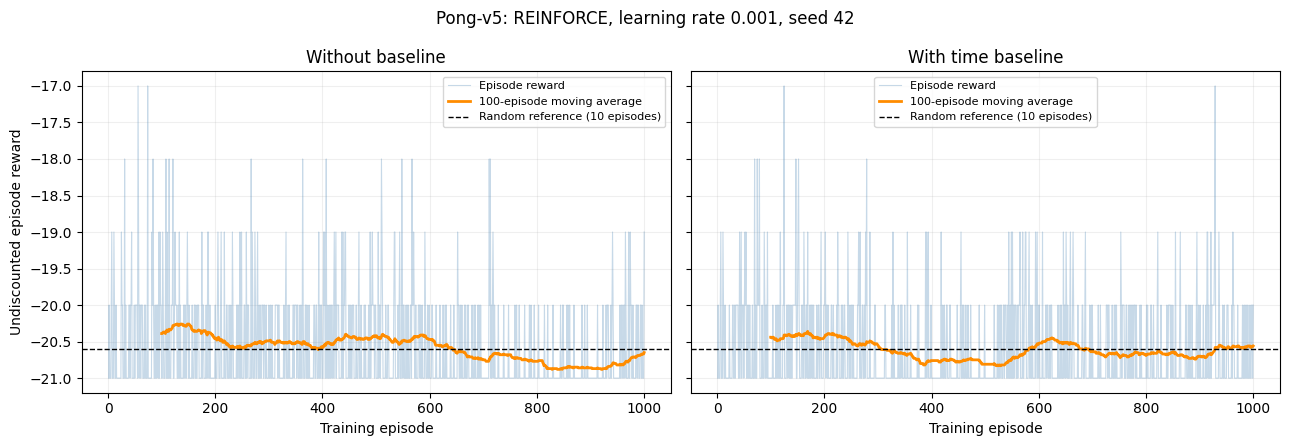

            method  episodes  first_100_mean_score  last_100_mean_score  best_100_mean_score  best_window_end  first_100_mean_discounted_return  last_100_mean_discounted_return
  Without baseline      1000              -20.3900             -20.6500             -20.2600              128                           -1.3536                          -1.2145
With time baseline      1000              -20.4400             -20.5600             -20.3600              169                           -1.3700                          -0.8635

Comparison plot saved to: pong_results/baseline_training_comparison.png
Baseline learning curve saved to: pong_runs/time_baseline_seed42_lr0001/learning_curve.png
No parameter updates performed.


In [46]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pong_comparison_dir = Path("pong_results")
pong_comparison_dir.mkdir(exist_ok=True)

pong_run_paths = {
    "Without baseline": Path("pong_runs/no_baseline_seed42_lr0001"),
    "With time baseline": Path("pong_runs/time_baseline_seed42_lr0001"),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
comparison_rows = []

for ax, (label, run_path) in zip(axes, pong_run_paths.items()):
    data = pd.read_csv(run_path / "training.csv")
    moving_mean = data["reward"].rolling(
        100, min_periods=100
    ).mean()

    ax.plot(
        data["episode"], data["reward"],
        color="steelblue", alpha=0.3, linewidth=0.8,
        label="Episode reward",
    )
    ax.plot(
        data["episode"], moving_mean,
        color="darkorange", linewidth=2,
        label="100-episode moving average",
    )
    ax.axhline(
        -20.60, color="black", linestyle="--", linewidth=1,
        label="Random reference (10 episodes)",
    )
    ax.set_title(label)
    ax.set_xlabel("Training episode")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

    best_index = moving_mean.idxmax()
    comparison_rows.append({
        "method": label,
        "episodes": len(data),
        "first_100_mean_score": data.head(100)["reward"].mean(),
        "last_100_mean_score": data.tail(100)["reward"].mean(),
        "best_100_mean_score": moving_mean.loc[best_index],
        "best_window_end": int(data.loc[best_index, "episode"]),
        "first_100_mean_discounted_return":
            data.head(100)["discounted_return"].mean(),
        "last_100_mean_discounted_return":
            data.tail(100)["discounted_return"].mean(),
    })

axes[0].set_ylabel("Undiscounted episode reward")
fig.suptitle("Pong-v5: REINFORCE, learning rate 0.001, seed 42")
fig.tight_layout()

comparison_plot = pong_comparison_dir / "baseline_training_comparison.png"
fig.savefig(comparison_plot, dpi=200, bbox_inches="tight")
plt.show()

# Save a standalone baseline learning curve for the report.
baseline_path = pong_run_paths["With time baseline"]
baseline_data = pd.read_csv(baseline_path / "training.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    baseline_data["episode"], baseline_data["reward"],
    color="steelblue", alpha=0.3, linewidth=0.8,
    label="Episode reward",
)
ax.plot(
    baseline_data["episode"],
    baseline_data["reward"].rolling(100, min_periods=100).mean(),
    color="darkorange", linewidth=2,
    label="100-episode moving average",
)
ax.set(
    title="Pong-v5: REINFORCE with a time-dependent baseline",
    xlabel="Training episode",
    ylabel="Undiscounted episode reward",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(
    baseline_path / "learning_curve.png",
    dpi=200, bbox_inches="tight",
)
plt.close(fig)

comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(
    pong_comparison_dir / "training_comparison.csv", index=False
)

print(comparison_table.to_string(index=False, float_format="%.4f"))
print("\nComparison plot saved to:", comparison_plot)
print("Baseline learning curve saved to:", baseline_path / "learning_curve.png")
print("No parameter updates performed.")

In [47]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

validation_dir = Path("pong_results/checkpoint_validation")
validation_dir.mkdir(parents=True, exist_ok=True)

validation_runs = {
    "no_baseline": Path("pong_runs/no_baseline_seed42_lr0001"),
    "time_baseline": Path("pong_runs/time_baseline_seed42_lr0001"),
}
validation_checkpoints = [200, 400, 600, 800, 1000]
validation_episode_count = 30

validation_rows = []
validation_episode_rows = []

torch.set_num_threads(1)

# Preserve the notebook's random-number state.
with torch.random.fork_rng(devices=[]):
    for method, run_path in validation_runs.items():
        print(f"\n{method.upper()}", flush=True)
        print("Checkpoint | Mean score | Sample SD | Mean discounted return")

        for checkpoint_episode in validation_checkpoints:
            checkpoint_path = (
                run_path / f"checkpoint_{checkpoint_episode:05d}.pt"
            )
            checkpoint = torch.load(
                checkpoint_path,
                map_location=pong_device,
                weights_only=True,
            )

            evaluation_policy = PongPolicy().to(pong_device)
            evaluation_policy.load_state_dict(
                checkpoint["policy_state_dict"]
            )
            evaluation_policy.eval()

            scores = []
            starting_returns = []
            evaluation_env = make_pong_env()

            try:
                for episode_index in range(validation_episode_count):
                    # Same seed protocol for every candidate.
                    # These seeds are separate from training.
                    environment_seed = 7_000_000 + episode_index
                    action_seed = 70_000 + episode_index
                    torch.manual_seed(action_seed)

                    trajectory = collect_pong_episode(
                        evaluation_env,
                        evaluation_policy,
                        reset_seed=environment_seed,
                    )

                    score = float(np.sum(trajectory["rewards"]))
                    starting_return = float(
                        discounted_returns(
                            trajectory["rewards"], 0.99
                        )[0]
                    )
                    scores.append(score)
                    starting_returns.append(starting_return)

                    validation_episode_rows.append({
                        "method": method,
                        "checkpoint_episode": checkpoint_episode,
                        "evaluation_episode": episode_index + 1,
                        "environment_seed": environment_seed,
                        "action_seed": action_seed,
                        "reward": score,
                        "discounted_return": starting_return,
                        "length": len(trajectory["rewards"]),
                        "terminated": trajectory["terminated"],
                        "truncated": trajectory["truncated"],
                    })
                    del trajectory

            finally:
                evaluation_env.close()

            row = {
                "method": method,
                "checkpoint_episode": checkpoint_episode,
                "checkpoint_path": str(checkpoint_path),
                "evaluation_episodes": validation_episode_count,
                "mean_score": float(np.mean(scores)),
                "sample_sd": float(np.std(scores, ddof=1)),
                "mean_discounted_return":
                    float(np.mean(starting_returns)),
            }
            validation_rows.append(row)

            # Save after every checkpoint so completed work is preserved.
            pd.DataFrame(validation_rows).to_csv(
                validation_dir / "checkpoint_summary.csv", index=False
            )
            pd.DataFrame(validation_episode_rows).to_csv(
                validation_dir / "episode_results.csv", index=False
            )

            print(
                f"{checkpoint_episode:10d} | "
                f"{row['mean_score']:10.3f} | "
                f"{row['sample_sd']:9.3f} | "
                f"{row['mean_discounted_return']:22.6f}",
                flush=True,
            )

validation_table = pd.DataFrame(validation_rows)

# Selection rule: higher mean score, then higher discounted return;
# if still tied, prefer the earlier checkpoint.
selected_pong_checkpoints = (
    validation_table.sort_values(
        ["method", "mean_score", "mean_discounted_return",
         "checkpoint_episode"],
        ascending=[True, False, False, True],
    )
    .groupby("method", sort=False)
    .head(1)
    .reset_index(drop=True)
)

selected_pong_checkpoints.to_csv(
    validation_dir / "selected_checkpoints.csv", index=False
)

print("\nSELECTED CHECKPOINTS")
print(selected_pong_checkpoints[
    ["method", "checkpoint_episode", "mean_score",
     "mean_discounted_return"]
].to_string(index=False))

print("\nResults saved in:", validation_dir)
print("No parameter updates performed.")


NO_BASELINE
Checkpoint | Mean score | Sample SD | Mean discounted return
       200 |    -20.533 |     0.629 |              -1.347487
       400 |    -20.533 |     0.629 |              -1.312699
       600 |    -20.700 |     0.702 |              -1.294767
       800 |    -20.867 |     0.434 |              -1.287419
      1000 |    -20.633 |     0.490 |              -1.258926

TIME_BASELINE
Checkpoint | Mean score | Sample SD | Mean discounted return
       200 |    -20.633 |     0.556 |              -1.209488
       400 |    -20.733 |     0.450 |              -1.050880
       600 |    -20.333 |     0.922 |              -1.128960
       800 |    -20.567 |     0.504 |              -0.944761
      1000 |    -20.500 |     0.682 |              -0.752151

SELECTED CHECKPOINTS
       method  checkpoint_episode  mean_score  mean_discounted_return
  no_baseline                 400  -20.533333               -1.312699
time_baseline                 600  -20.333333               -1.128960

Results


no_baseline: checkpoint 400, resuming at episode 1
Completed 100/500
Completed 200/500
Completed 300/500
Completed 400/500
Completed 500/500


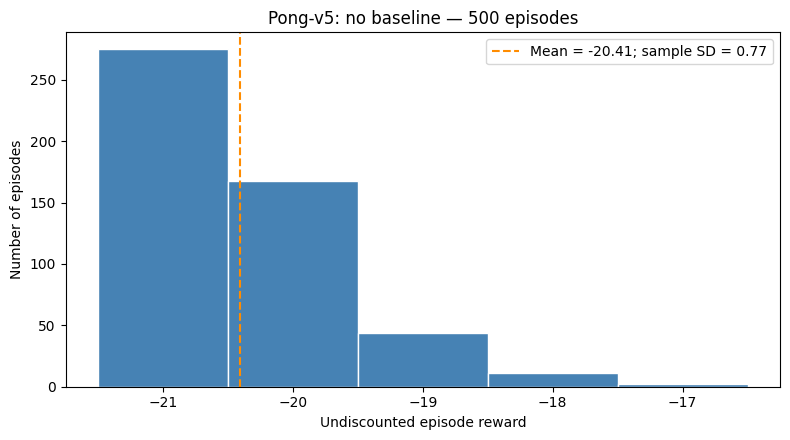


FINAL RESULTS: no_baseline
Mean reward: -20.406
Sample SD: 0.774
Approximate 95% CI: [-20.474, -20.338]
Range: [-21, -17]
Truncated episodes: 0
Saved in: pong_runs/no_baseline_seed42_lr0001/final_evaluation_checkpoint00400

time_baseline: checkpoint 600, resuming at episode 1
Completed 100/500
Completed 200/500
Completed 300/500
Completed 400/500
Completed 500/500


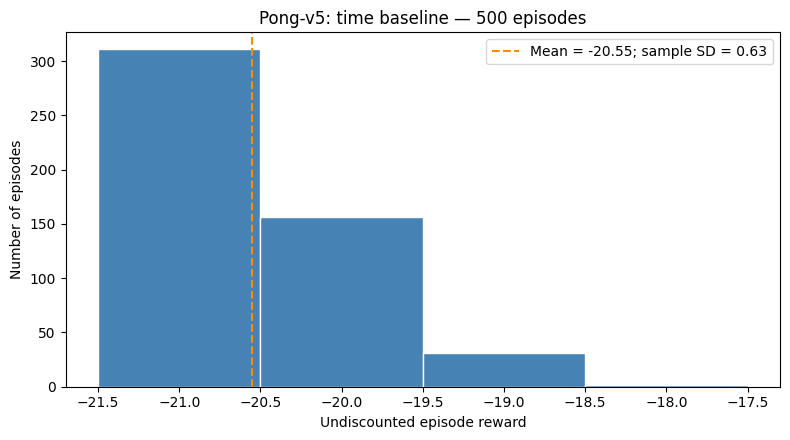


FINAL RESULTS: time_baseline
Mean reward: -20.552
Sample SD: 0.629
Approximate 95% CI: [-20.607, -20.497]
Range: [-21, -18]
Truncated episodes: 0
Saved in: pong_runs/time_baseline_seed42_lr0001/final_evaluation_checkpoint00600

Both final evaluations complete. No parameter updates performed.


In [48]:
import csv
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

selection = pd.read_csv(
    "pong_results/checkpoint_validation/selected_checkpoints.csv"
)
final_summaries = []
torch.set_num_threads(1)

with torch.random.fork_rng(devices=[]):
    for _, selected in selection.iterrows():
        method = selected["method"]
        checkpoint_path = Path(selected["checkpoint_path"])
        checkpoint_episode = int(selected["checkpoint_episode"])

        output_dir = checkpoint_path.parent / (
            f"final_evaluation_checkpoint{checkpoint_episode:05d}"
        )
        output_dir.mkdir(parents=True, exist_ok=True)
        scores_path = output_dir / "episode_scores.csv"

        # Resume only complete, consecutively numbered episodes.
        if scores_path.exists():
            previous = pd.read_csv(scores_path)
            if previous["evaluation_episode"].tolist() != list(
                range(1, len(previous) + 1)
            ):
                raise RuntimeError("Evaluation log needs inspection.")
            completed = len(previous)
            if completed > 500:
                raise RuntimeError("Unexpected evaluation episode count.")
        else:
            completed = 0

        checkpoint = torch.load(
            checkpoint_path, map_location=pong_device, weights_only=True
        )
        final_policy = PongPolicy().to(pong_device)
        final_policy.load_state_dict(checkpoint["policy_state_dict"])
        final_policy.eval()

        columns = [
            "evaluation_episode", "environment_seed", "action_seed",
            "reward", "discounted_return", "length",
            "terminated", "truncated",
        ]

        print(
            f"\n{method}: checkpoint {checkpoint_episode}, "
            f"resuming at episode {completed + 1}",
            flush=True,
        )

        evaluation_env = make_pong_env()
        try:
            with scores_path.open(
                "a" if scores_path.exists() else "w", newline=""
            ) as log_file:
                writer = csv.DictWriter(log_file, fieldnames=columns)
                if log_file.tell() == 0:
                    writer.writeheader()

                for episode_index in range(completed, 500):
                    environment_seed = 9_000_000 + episode_index
                    action_seed = 90_000 + episode_index
                    torch.manual_seed(action_seed)

                    trajectory = collect_pong_episode(
                        evaluation_env, final_policy,
                        reset_seed=environment_seed,
                    )
                    rewards = trajectory["rewards"]

                    writer.writerow({
                        "evaluation_episode": episode_index + 1,
                        "environment_seed": environment_seed,
                        "action_seed": action_seed,
                        "reward": float(np.sum(rewards)),
                        "discounted_return": float(
                            discounted_returns(rewards, 0.99)[0]
                        ),
                        "length": len(rewards),
                        "terminated": trajectory["terminated"],
                        "truncated": trajectory["truncated"],
                    })
                    log_file.flush()
                    del trajectory

                    if (episode_index + 1) % 100 == 0:
                        print(
                            f"Completed {episode_index + 1}/500",
                            flush=True,
                        )
        finally:
            evaluation_env.close()

        results = pd.read_csv(scores_path)
        scores = results["reward"].to_numpy(dtype=float)
        mean = float(scores.mean())
        sd = float(scores.std(ddof=1))
        margin = 1.96 * sd / np.sqrt(len(scores))

        summary = {
            "method": method,
            "checkpoint_episode": checkpoint_episode,
            "checkpoint_path": str(checkpoint_path),
            "evaluation_episodes": len(scores),
            "policy": "stochastic; actions sampled from frozen policy",
            "environment_seed_start": 9_000_000,
            "action_seed_start": 90_000,
            "mean_reward": mean,
            "sample_standard_deviation": sd,
            "approximate_95_percent_ci": [mean - margin, mean + margin],
            "minimum_reward": float(scores.min()),
            "maximum_reward": float(scores.max()),
            "positive_score_fraction": float(np.mean(scores > 0)),
            "mean_discounted_return":
                float(results["discounted_return"].mean()),
            "truncated_episodes":
                int(results["truncated"].astype(str).str.lower().eq("true").sum()),
        }
        (output_dir / "summary.json").write_text(
            json.dumps(summary, indent=2)
        )
        final_summaries.append(summary)

        fig, ax = plt.subplots(figsize=(8, 4.5))
        bins = np.arange(scores.min() - 0.5, scores.max() + 1.5, 1)
        ax.hist(scores, bins=bins, color="steelblue", edgecolor="white")
        ax.axvline(
            mean, color="darkorange", linestyle="--",
            label=f"Mean = {mean:.2f}; sample SD = {sd:.2f}",
        )
        ax.set(
            title=f"Pong-v5: {method.replace('_', ' ')} — 500 episodes",
            xlabel="Undiscounted episode reward",
            ylabel="Number of episodes",
        )
        ax.legend()
        fig.tight_layout()
        fig.savefig(
            output_dir / "reward_histogram.png",
            dpi=200, bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

        print(f"\nFINAL RESULTS: {method}")
        print(f"Mean reward: {mean:.3f}")
        print(f"Sample SD: {sd:.3f}")
        print(
            f"Approximate 95% CI: "
            f"[{mean - margin:.3f}, {mean + margin:.3f}]"
        )
        print(f"Range: [{scores.min():.0f}, {scores.max():.0f}]")
        print(f"Truncated episodes: {summary['truncated_episodes']}")
        print("Saved in:", output_dir)

print("\nBoth final evaluations complete. No parameter updates performed.")

In [49]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

pv_checkpoint_path = Path(
    "pong_runs/time_baseline_seed42_lr0001/checkpoint_00600.pt"
)
pv_dir = pv_checkpoint_path.parent / "gradient_variance"
pv_dir.mkdir(parents=True, exist_ok=True)

pv_checkpoint = torch.load(
    pv_checkpoint_path, map_location=pong_device, weights_only=True
)

torch.set_num_threads(1)

# Online, numerically stable variance across gradient vectors.
class GradientMoments:
    def __init__(self):
        self.count = 0
        self.mean = None
        self.m2 = None

    def add(self, vector):
        vector = np.asarray(vector, dtype=np.float64)
        self.count += 1
        if self.mean is None:
            self.mean = vector.copy()
            self.m2 = np.zeros_like(vector)
        else:
            delta = vector - self.mean
            self.mean += delta / self.count
            self.m2 += delta * (vector - self.mean)

    def total_variance(self):
        # Sum of sample variances across all parameters:
        # the trace of the gradient covariance matrix.
        return float(self.m2.sum() / (self.count - 1))

pv_without = GradientMoments()
pv_with = GradientMoments()
pv_episode_rows = []

with torch.random.fork_rng(devices=[]):
    pv_policy = PongPolicy().to(pong_device)
    pv_policy.load_state_dict(pv_checkpoint["policy_state_dict"])
    pv_policy.eval()

    pv_saved_baseline = (
        pv_checkpoint["time_baseline"].cpu().numpy().copy()
    )
    pv_env = make_pong_env()

    try:
        for episode_index in range(100):
            torch.manual_seed(80_000 + episode_index)

            trajectory = collect_pong_episode(
                pv_env, pv_policy,
                reset_seed=8_000_000 + episode_index,
            )

            # Unseen timesteps use zero; no baseline fitting on audit data.
            frozen_baseline = np.pad(
                pv_saved_baseline,
                (0, max(
                    0, len(trajectory["rewards"]) - len(pv_saved_baseline)
                )),
            )

            gradient_norms = {}

            for label, baseline, moments in [
                ("without", None, pv_without),
                ("with", frozen_baseline, pv_with),
            ]:
                pv_policy.zero_grad(set_to_none=True)

                accumulate_pong_gradient(
                    pv_policy,
                    trajectory,
                    gamma=0.99,
                    baseline=baseline,
                    episode_divisor=1,
                    chunk_size=256,
                )

                gradient = torch.cat([
                    parameter.grad.detach().reshape(-1)
                    for parameter in pv_policy.parameters()
                ]).cpu().numpy().astype(np.float64)

                if not np.isfinite(gradient).all():
                    raise RuntimeError("Nonfinite gradient in variance audit.")

                moments.add(gradient)
                gradient_norms[label] = float(np.linalg.norm(gradient))
                del gradient

            pv_episode_rows.append({
                "episode": episode_index + 1,
                "environment_seed": 8_000_000 + episode_index,
                "action_seed": 80_000 + episode_index,
                "reward": float(np.sum(trajectory["rewards"])),
                "length": len(trajectory["rewards"]),
                "gradient_norm_without": gradient_norms["without"],
                "gradient_norm_with": gradient_norms["with"],
            })

            del trajectory

            if (episode_index + 1) % 25 == 0:
                print(
                    f"Processed {episode_index + 1}/100 episodes",
                    flush=True,
                )
    finally:
        pv_env.close()
        pv_policy.zero_grad(set_to_none=True)

variance_without = pv_without.total_variance()
variance_with = pv_with.total_variance()
variance_ratio = (
    variance_with / variance_without
    if variance_without > 0 else None
)

pv_summary = {
    "checkpoint": str(pv_checkpoint_path),
    "independent_trajectories": 100,
    "variance_measure": "trace of sample gradient covariance",
    "without_baseline": variance_without,
    "with_baseline": variance_with,
    "variance_ratio_with_over_without": variance_ratio,
    "estimated_reduction_percent": (
        100 * (1 - variance_ratio)
        if variance_ratio is not None else None
    ),
    "baseline_frozen": True,
    "parameter_updates": 0,
}

(pv_dir / "summary.json").write_text(json.dumps(pv_summary, indent=2))
pd.DataFrame(pv_episode_rows).to_csv(
    pv_dir / "episode_diagnostics.csv", index=False
)
np.savez_compressed(
    pv_dir / "gradient_moments.npz",
    count=pv_without.count,
    mean_without=pv_without.mean,
    m2_without=pv_without.m2,
    mean_with=pv_with.mean,
    m2_with=pv_with.m2,
)

print("\nFROZEN-POLICY GRADIENT VARIANCE")
print(f"Without baseline: {variance_without:.6e}")
print(f"With baseline:    {variance_with:.6e}")
if variance_ratio is not None:
    print(f"Variance ratio (with / without): {variance_ratio:.6f}")
    print(f"Estimated reduction: {100 * (1 - variance_ratio):.2f}%")
print("Parameter updates: 0")
print("Saved in:", pv_dir)

Processed 25/100 episodes
Processed 50/100 episodes
Processed 75/100 episodes
Processed 100/100 episodes

FROZEN-POLICY GRADIENT VARIANCE
Without baseline: 6.264655e+02
With baseline:    8.816024e+01
Variance ratio (with / without): 0.140726
Estimated reduction: 85.93%
Parameter updates: 0
Saved in: pong_runs/time_baseline_seed42_lr0001/gradient_variance


In [50]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

backup_folders = [Path("pong_runs"), Path("pong_results")]
archive_path = Path("pong_results_backup.zip")

for folder in backup_folders:
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {folder}")

file_count = 0
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for folder in backup_folders:
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                archive.write(path, arcname=path.as_posix())
                file_count += 1

print("Created:", archive_path)
print("Files included:", file_count)
print(f"Archive size: {archive_path.stat().st_size / (1024**2):.2f} MB")

files.download(str(archive_path))

Created: pong_results_backup.zip
Files included: 55
Archive size: 227.52 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>